# MSc in AI Capstone #6 — Agentic AI Systems
## HKDSE ICT Adaptive Practice Tutor: a multi-agent system over past-paper questions


| Item | Detail |
|---|---|
| Domain | Education — Hong Kong HKDSE ICT, Paper 1A (multiple choice) |
| System type | Multi-agent, orchestrator–worker, tool-calling |
| Framework | `smolagents` (`ToolCallingAgent`, managed agents, `@tool`) with Claude Haiku 4.5 via `LiteLLMModel`, configured in Section 3.8 |
| Data | `final_dataset.csv` (past-paper question bank, schema v1.6+ includes `cluster`/`cluster_desc` for shared-context question clusters), `ict_curriculum.md` (official curriculum text) |

**How to run:** keep the data files in `./data/` (or next to the notebook): `final_dataset.csv`, `ict_curriculum.md` and the question image folders (`data/question/...`); put `architecture_diagram.png` next to the notebook; then run all cells **in order, top to bottom** (the Task 4 scenarios share one session and one Orchestrator memory). Tasks 1–3 need no API key. The live scenarios in Task 4 need `ANTHROPIC_API_KEY` in a `.env` file next to the notebook (model `claude-haiku-4-5-20251001` through the course LiteLLM proxy, configured in Section 3.8); without a working key each scenario prints a skip notice instead. Python dependencies are listed in `requirements.txt`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_colwidth", 80)
DATA_PATH = next((p for p in [Path("final_dataset.csv"), Path("data/final_dataset.csv")] if p.exists()), None)
assert DATA_PATH is not None, "Place final_dataset.csv next to this notebook (or in ./data/)."
print("Using dataset:", DATA_PATH)

Using dataset: data\final_dataset.csv


---
# Task 1 — Define the Agentic Task and System Scope

## 1.1 Goal of the system

> **Run an adaptive practice session for a secondary-school student preparing for HKDSE ICT Paper 1A.** The system decides which real past-paper question(s) to serve next based on what the student has shown they know and do not know, presents each question faithfully, grades the answer deterministically, and explains the result using the official ICT curriculum text. It can also answer questions about the past-paper bank itself, such as how difficulty varies across years and modules, and compare the student's results with cohort difficulty.

The system succeeds when, within a session:

1. **Every question served is a real, verified past-paper question** — the system never invents or rewrites questions.
2. **The correct answer is never revealed before the student has attempted the question.**
3. **Mastery is tracked per curriculum subcategory** by an explicit, auditable rule, and the next-question choice visibly responds to it.
4. **Explanations are traceable** - The explanation tool returns the curriculum text for the question’s tags, or flags that no grounding source exists for that topic. This is a guarantee about what the tool supplies; the Tutor’s final wording is written by the model and is not checked against it (Task 4, Scenarios 2 and 3).
5. **Questions that only make sense together are always served together.**
6. **Analysis answers are computed by code from the bank, reported with their sample sizes, and never presented as predictions.**

## 1.2 Single-agent or multi-agent?

**Multi-agent: one Orchestrator and four worker agents** (Question Selector, Explainer, Progress Tracker, Question Analyst).

The task contains four responsibilities that differ in what data they may touch and in how they can fail:

| Responsibility | Needs | Main failure risk | Therefore |
|---|---|---|---|
| Choosing the next question | Read access to the question bank, **but not the answers** | Biased or repetitive selection; serving half of a question cluster | Own agent with answer-free tools and deterministic filtering |
| Presenting questions and explaining answers | Curriculum text; a *recorded* attempt | Hallucinated explanations; leaking the answer early | Own agent that **cannot read the answer key** and only receives it inside a recorded attempt |
| Tracking what the student knows | Answer key; the only write access to session state | Wrong credit, double counting, state corrupted by an LLM | Own agent with deterministic tools and sole write access |
| Analysing the question bank | Read access to question-bank **metadata** (year, tags, `cohort_pct`, question features), **not the answer key** | Invented or misleading statistics; over-reading a rough difficulty signal | Own agent whose tools compute every number in code and return caveats with it |

**Why not one agent with sixteen tools?** A single agent could call the same functions, but every safeguard above would then rest on prompt wording alone. Splitting the roles lets the safeguards be enforced by *what each agent is able to call* (least privilege), which is easier to test and to explain. **The cost** is more LLM calls, more tokens and higher latency per turn, and the orchestrator must pass context between workers. Task 4 shows the cost: a start-of-session turn took 14 model steps across five agent runs (Scenario 1) and an answer turn 9 steps across three (Scenario 2), while a refusal took one step (Scenarios 5 and 9), counted from the step headers in each scenario's log.

## 1.3 Decisions each agent is responsible for

The deliberate split between **LLM judgement** and **deterministic code** is the central design idea of this system.

| Agent | Decision | Inputs | Mechanism |
|---|---|---|---|
| **Orchestrator** | What kind of turn is this (start/next, answer, explain, reveal request, progress, end, unsupported)? Which worker(s), in what order? Is a precondition missing? How to phrase the reply? | Student message; conversation context | LLM reasoning guided by explicit routing rules (Section 2.3) |
| **Question Selector** | Which question or question cluster to serve next | Target tags, difficulty band, ids to exclude | **Deterministic** filtering in tool code (tags, `cohort_pct` band, exclusions); the LLM translates the request into those parameters and takes the first usable result |
| **Question Analyst** | Which analysis answers the request, with which parameters? How to describe the result and its caveats? | Analysis request; for the cohort comparison, the student's mastery summary, which `compare_student_to_cohort` fetches itself | **Deterministic** statistics in tool code; the LLM chooses the tool, fills the parameters and words the findings **using only the returned numbers and caveats** |
| **Progress Tracker** | Is this attempt valid (a unit is pending, no duplicate scoring)? Was it correct? Which tags change? Which tags are weak? | Pending unit, chosen letter, answer key | **Deterministic** tool code only |
| **Explainer** | How to present the unit; how to phrase feedback | Question unit; recorded attempt; curriculum text | LLM wording **constrained to the content returned by its tools** |

**Selection policy (design intent).** (1) Honour a topic the student asks for. (2) Otherwise prefer tags with low accuracy, then tags not yet attempted. (3) Pick a difficulty band from `cohort_pct` that matches the student's current accuracy on that tag. (4) Never repeat a question within a session. In Task 3 the tool code enforces only the filtering; the weak-tag and difficulty-band choices are made by the agents when they fill the tool parameters, so they are not guaranteed (see the Observed note after Scenario 1).

## 1.4 Actions and tools available

Sixteen tools in total, each assigned to exactly one agent. The Orchestrator has **no data tools**: it can only delegate.

| # | Tool | Agent | Reads | Writes | Purpose |
|---|---|---|---|---|---|
| 1 | `search_questions(tags, band, exclude)` | Selector | Question bank (answers hidden) | — | Filter candidate questions by tag and difficulty band |
| 2 | `get_question_cluster(qn_id)` | Selector | Question bank (`cluster`/`cluster_desc`) | — | Resolve a question to its full served unit (all members, shared preamble text, shared image) |
| 3 | `render_question(qn_id)` | Explainer | Question bank (looks the unit up itself) | — | Format a unit for display; options kept verbatim; image path surfaced, not interpreted |
| 4 | `get_curriculum_reference(tag)` | Explainer | `ict_curriculum.md` | — | Official learning-outcome text for a tag |
| 5 | `explain_answer(qn_id)` | Explainer | `SESSION.history` (already-graded attempts only) | — | Build a feedback package from a **recorded** attempt |
| 6 | `register_served_unit(qn_id)` | Tracker | — | SessionState | Mark a unit as served and awaiting an answer |
| 7 | `record_attempt(qn_id, letter)` | Tracker | Answer key | SessionState | Grade by letter; update mastery for every tag |
| 8 | `get_mastery_summary()` | Tracker | SessionState | — | Per-tag accuracy, weak tags, ids already seen |
| 9 | `get_session_stats()` | Tracker | SessionState | — | Attempts, overall accuracy, clusters covered |
| 10 | `difficulty_by_year(tags)` | Analyst | Question bank (metadata) | — | Mean and median `cohort_pct` and question count per year, optionally for chosen tags |
| 11 | `difficulty_by_topic(level)` | Analyst | Question bank (metadata) | — | The same statistics by module or by subcategory tag |
| 12 | `compare_question_features(feature)` | Analyst | Question bank (metadata) | — | Compare image questions against text-only ones, single-label against multi-label, and clustered against standalone |
| 13 | `rank_questions(order, tags, limit)` | Analyst | Question bank (metadata) | — | Hardest or easiest questions, returned as ids and metadata only |
| 14 | `compare_student_to_cohort()` | Analyst | Question bank (metadata); calls `get_mastery_summary()` itself | — | The student's per-tag accuracy next to cohort difficulty for the same tags |
| 15 | `list_tags()` | Selector | Static tag vocabulary (`TAG_DESCRIPTIONS`, from the classification key) | — | Map a topic in plain words to the real subcategory tag codes before searching |
| 16 | `get_pending_unit()` | Tracker | SessionState (`pending_unit`) | — | Return the unit currently awaiting an answer, or `None`, so grading never depends on the Orchestrator's memory alone |

The aggregate Analyst tools (`difficulty_by_year`, `difficulty_by_topic`, `compare_question_features`) return a results table, the sample size behind each row, and a list of caveats (for example a low-sample warning); `rank_questions` returns ids and metadata only, and `compare_student_to_cohort` returns the student's attempt counts and the cohort mean without the cohort's n. The charts in Section 1.7 are drawn with Matplotlib directly from the question bank.

## 1.5 Why this task needs reasoning, decision-making and tool use

- **Reasoning:** each turn must be interpreted ("can you do a networking one?", "B and D", "why?", "just tell me the answer") and mapped to a valid action sequence, with preconditions checked (an answer needs a pending question; an explanation needs a recorded attempt). An analysis request ("are networking questions getting harder?") must be mapped to the right analysis and its result described with the right caveats.
- **Decision-making:** the system chooses *what to teach next* from 500+ candidates using evolving evidence about the student.
- **Tool use:** all facts — questions, answer keys, curriculum text, mastery — come from tools, never from the model's memory.

## 1.6 System requirements checklist

| Requirement (from the instructions) | How this design meets it |
|---|---|
| Implementable with course tools and frameworks | `smolagents` `ToolCallingAgent` with managed agents and `@tool` functions |
| Explicit reasoning or decision logic | Orchestrator routing and precondition rules (Section 2.3); deterministic filtering, grading and mastery rules (Sections 1.3, 1.7, 2.4) |
| Limited memory, state or context handling | In-session `SessionState` plus orchestrator conversation context; no long-term persistence (Section 2.4) |
| At least one tool, function or external capability | Sixteen tools (Section 1.4) |
| Appropriate for academic use | Public past-paper content used for non-commercial study; source rights remain with the original publisher (HKEAA); no personal data collected; the system presents itself as a practice aid, not an assessment |

## 1.7 Data scope and handling rules

The question bank comes from `final_dataset.csv` (one row per question). The rules below were fixed **before** design so that the architecture is built around the data the agent can actually use.

| # | Rule | Reason |
|---|---|---|
| 1 | Exclude every 2025 question | All 40 are `unclassified` because that paper has not been through classification, so they have no topic tags |
| 2 | Exclude every question whose `correct_answer` is `*` | A withdrawn question has no valid key and must never be scored |
| 3 | Keep other `unclassified` questions and label them `general_knowledge` | They are valid questions without a syllabus tag; mastery for them is tracked in a catch-all bucket and they have no curriculum grounding |
| 4 | Images: surface the image file to the student, never interpret it | The agent has no vision step; this is a stated system boundary |
| 5 | Multi-label questions: **full credit to every tag** | `qn_type_id` can hold several tags and none is marked primary; crediting all is simple and auditable. It can blur attribution on a miss (known limitation) |
| 6 | `answer_options` is an **opaque display blob** | Options may be a list, a Markdown table or the `[IMAGE]` sentinel. The system renders it verbatim and grades only by comparing the chosen **letter** with `correct_answer` |
| 7 | Questions that depend on shared context are one **served unit** | Resolved directly from the dataset's `cluster`/`cluster_desc` fields (schema v1.6): all questions sharing an identical `cluster_desc` are one cluster. A unit is always served and registered as a whole, while each member is still scored separately |
| 8 | `cohort_pct` is a **descriptive, cohort-specific** difficulty indicator | It is the share of candidates answering correctly in that year, not a calibrated difficulty scale across years. Every analysis result reports its sample size, and tag-level groups overlap (a multi-label question counts under each of its tags), so they must not be summed |

In [3]:
raw = pd.read_csv(DATA_PATH)

excl_2025      = (raw["paper_year"] == 2025) & (raw["qn_type_id"] == "unclassified")
excl_withdrawn = raw["correct_answer"] == "*"
bank = raw[~excl_2025 & ~excl_withdrawn].copy()
bank["subcats"] = bank["qn_type_id"].replace("unclassified", "general_knowledge").str.split(";")

tags = bank["subcats"].explode()
summary = pd.Series({
    "Rows in final_dataset.csv": len(raw),
    "Excluded: 2025 (unclassified)": int(excl_2025.sum()),
    "Excluded: withdrawn (correct_answer = *)": int(excl_withdrawn.sum()),
    "Usable question bank": len(bank),
    "Years covered": f"{bank['paper_year'].min()}-{bank['paper_year'].max()}",
    "Rows labelled general_knowledge": int((bank["qn_type_id"] == "unclassified").sum()),
    "Multi-label rows (more than one tag)": int((bank["subcats"].str.len() > 1).sum()),
    "Distinct curriculum tags (excl. general_knowledge)": int(tags[tags != "general_knowledge"].nunique()),
    "Rows with a question image": int(bank["qn_image_filename"].notna().sum()),
    "Rows missing cohort_pct": int(bank["cohort_pct"].isna().sum()),
}, name="value")
summary.to_frame()

,value
Rows in final_dataset.csv,560
Excluded: 2025 (unclassified),40
Excluded: withdrawn (correct_answer = *),1
Usable question bank,519
Years covered,2012-2024
Rows labelled general_knowledge,38
Multi-label rows (more than one tag),61
Distinct curriculum tags (excl. general_knowledge),25
Rows with a question image,132
Rows missing cohort_pct,0


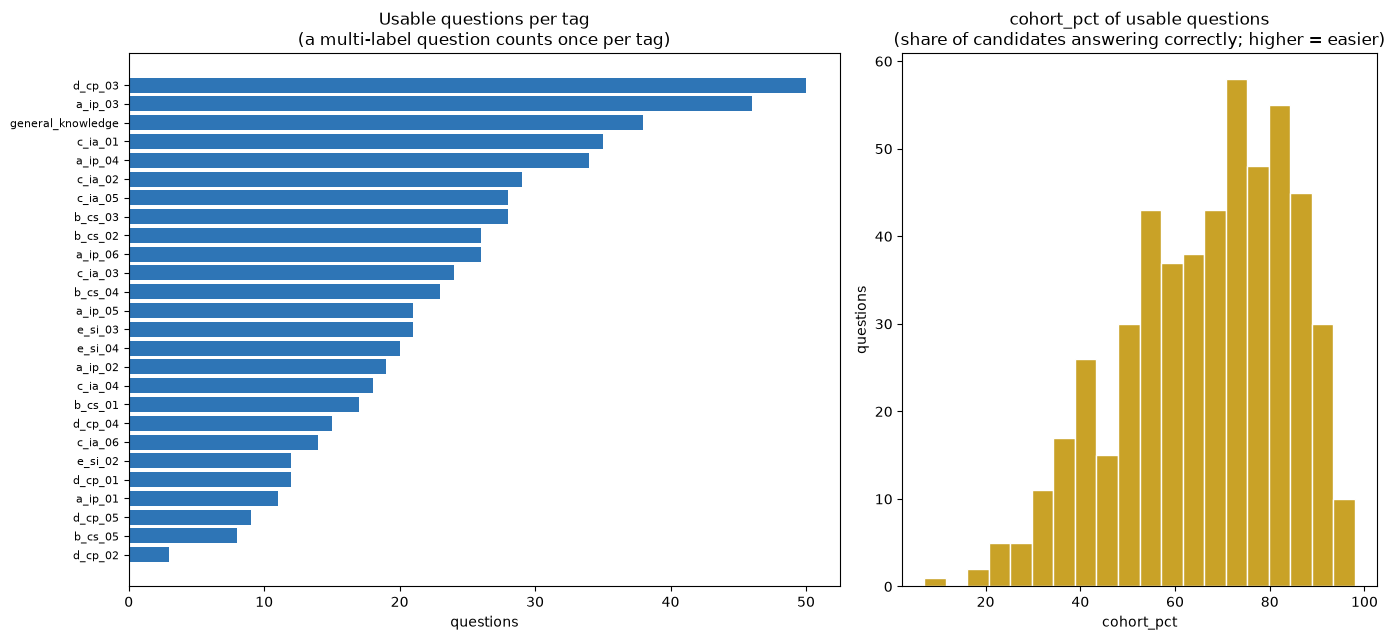

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})

counts = tags.value_counts().sort_values()
axes[0].barh(counts.index, counts.values, color="#2E75B6")
axes[0].set_title("Usable questions per tag\n(a multi-label question counts once per tag)")
axes[0].set_xlabel("questions")
axes[0].tick_params(axis="y", labelsize=8)

axes[1].hist(bank["cohort_pct"].dropna(), bins=20, color="#C9A227", edgecolor="white")
axes[1].set_title("cohort_pct of usable questions\n(share of candidates answering correctly; higher = easier)")
axes[1].set_xlabel("cohort_pct")
axes[1].set_ylabel("questions")

plt.tight_layout()
plt.show()

**Reading the output.** Coverage is uneven: tag counts range from 3 questions (`d_cp_02`) to 50 (`d_cp_03`), so for thin tags the selector can run out of unseen questions in a single session and must handle that case (Task 3). `cohort_pct` spans a wide range, which gives the selector a real, empirical difficulty signal rather than one invented by the system. It reflects each year's cohort, so it is not a calibrated difficulty scale across years (see tradeoffs in Section 2.5).

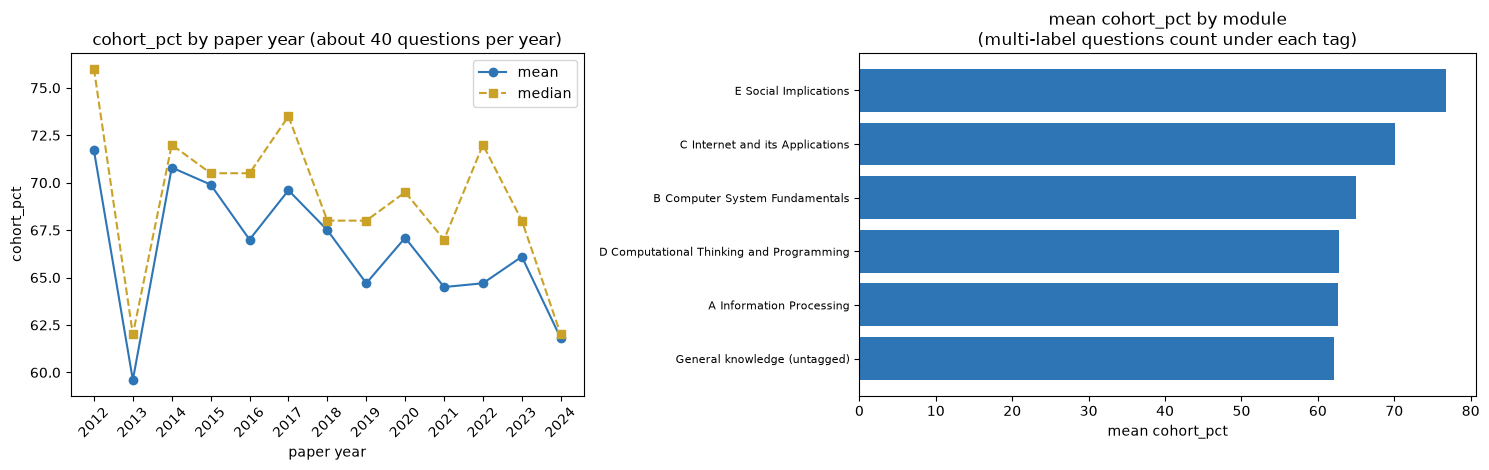

paper_year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
n,40.0,40.0,40.0,40.0,40.0,40.0,39.0,40.0,40.0,40.0,40.0,40.0,40.0
mean,71.7,59.6,70.8,69.9,67.0,69.6,67.5,64.7,67.1,64.5,64.7,66.1,61.8
median,76.0,62.0,72.0,70.5,70.5,73.5,68.0,68.0,69.5,67.0,72.0,68.0,62.0


,n,mean,median
module,,,
A Information Processing,157,62.7,63.0
B Computer System Fundamentals,102,65.0,63.0
C Internet and its Applications,148,70.1,72.0
D Computational Thinking and Programming,89,62.8,68.0
E Social Implications,53,76.8,81.0
General knowledge (untagged),38,62.1,64.5


In [5]:
from IPython.display import display

MODULES = {"a": "A Information Processing", "b": "B Computer System Fundamentals",
           "c": "C Internet and its Applications", "d": "D Computational Thinking and Programming",
           "e": "E Social Implications", "g": "General knowledge (untagged)"}

by_year = bank.groupby("paper_year")["cohort_pct"].agg(n="count", mean="mean", median="median").round(1)
t = bank.explode("subcats")
t["module"] = t["subcats"].str[0].map(MODULES)
by_module = t.groupby("module")["cohort_pct"].agg(n="count", mean="mean", median="median").round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].plot(by_year.index, by_year["mean"], marker="o", color="#2E75B6", label="mean")
axes[0].plot(by_year.index, by_year["median"], marker="s", ls="--", color="#C9A227", label="median")
axes[0].set_title("cohort_pct by paper year (about 40 questions per year)")
axes[0].set_xlabel("paper year"); axes[0].set_ylabel("cohort_pct"); axes[0].legend()
axes[0].set_xticks(by_year.index); axes[0].tick_params(axis="x", rotation=45)

bm = by_module["mean"].sort_values()
axes[1].barh(bm.index, bm.values, color="#2E75B6")
axes[1].set_title("mean cohort_pct by module\n(multi-label questions count under each tag)")
axes[1].set_xlabel("mean cohort_pct"); axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

display(by_year.T)
display(by_module)

**Variation the Analyst works with.** Mean `cohort_pct` differs across paper years (about 60% in 2013 to 72% in 2012) and across modules (about 63% for modules A and D to 77% for module E). Some of the year-to-year gap may reflect the cohort that sat the paper rather than the paper itself. That is why the Analyst must return sample sizes and caveats with every result and must not claim that one paper was "harder".

## 1.8 Intended behaviour and boundaries

**In scope**
- Practice sessions over the usable question bank, chosen by topic request or by the student's weak tags.
- Showing a question or question cluster, then accepting the student's answer letters.
- Deterministic grading, per-tag mastery tracking and progress summaries within one session.
- Curriculum-grounded explanations after an attempt.
- Descriptive analysis of the past-paper bank (difficulty by year, module and question feature; hardest and easiest questions) and a comparison of the student's session accuracy with cohort difficulty.

**Out of scope**
- Writing, rewriting or generating new questions.
- Interpreting images, diagrams or code screenshots.
- Free-text or open-ended marking; the system handles multiple choice only.
- Predicting exam grades, forecasting what will appear in a future paper, or giving official guidance.
- Explaining *why* a question was hard; the Analyst makes no causal claims (by instruction; Scenario 7 shows the reply can still drift).
- Saving progress between sessions or identifying individual students.
- Replacing a teacher; it is a practice aid.

**Hard rules (invariants the tools must enforce; rules 1 and 5 hold at tool level only)**
1. The answer key is never shown before an attempt is recorded.
2. A question can be scored only once per session, and only if it was served and is pending.
3. Excluded questions (2025 and withdrawn) are unreachable, because they are removed at the data layer rather than avoided by instruction.
4. A question cluster is never served in part.
5. The explanation tool returns curriculum text for the question’s tags, or explicitly flags the tag as ungrounded. This is enforced at tool level only; the wording of the Tutor’s reply is not checked against that text.
6. Every statistic comes from tool code, and aggregate statistics are reported with their sample size; small groups carry an explicit low-sample warning.

---
# Task 2 — Design the Agent Architecture

## 2.1 Components: persona, reasoning loop, memory and tools

All five agents run the same kind of **think → call a tool → observe** loop (a `ToolCallingAgent` with a step limit). They differ in persona, tools and memory.

| Agent | Persona (system-prompt role) | Reasoning loop | Memory | Tools |
|---|---|---|---|---|
| **Orchestrator** | Patient study coach for a secondary student: friendly, concise, never gives away an answer unprompted. Knows the routing rules but holds no data | Classify intent → check preconditions → delegate in the right order → compose reply | **Conversation context kept across turns** (`run_turn` calls `orchestrator_agent.run(..., reset=False)` - its omission was an observed failure, not a hypothetical one: see the note at the start of Task 4); no direct access to session state | None (delegates only) |
| **Question Selector** | Neutral question librarian: returns what the parameters ask for, nothing more | Map the request to tool parameters → call tools → return one unit | **Stateless per call** | `list_tags`, `search_questions`, `get_question_cluster` |
| **Explainer** | Clear ICT teacher: explains only from supplied material and says so when material is missing | Given a qn_id, look up the question (or an already-graded attempt) and format it, or turn it plus curriculum text into feedback | **Stateless per call** | `render_question`, `get_curriculum_reference`, `explain_answer` |
| **Question Analyst** | Careful data analyst: describes what the data shows with sample sizes and caveats; never predicts and never claims causes | Map the request to an analysis tool and parameters → call it → describe the returned table and caveats | **Stateless per call** | `difficulty_by_year`, `difficulty_by_topic`, `compare_question_features`, `rank_questions`, `compare_student_to_cohort` |
| **Progress Tracker** | Strict record-keeper: records facts, never interprets them | Validate → record → report | **Stateless per call; sole writer of `SessionState`** | `register_served_unit`, `record_attempt`, `get_mastery_summary`, `get_session_stats`, `get_pending_unit` |

**Memory design.** There are three layers, each with a different lifetime:
1. **Working memory** — each agent's own step history within one call (cleared after the call for workers).
2. **Conversation memory** — held only by the Orchestrator across turns, so it can resolve "that one" or "the next one". This depends on calling `orchestrator_agent.run(..., reset=False)`; without it every turn starts blind to what was just served or discussed, which defeats this layer entirely (see the note at the start of Task 4).
3. **Session memory** — `SessionState`, an in-memory object that is the single source of truth for what has been served, answered and learned (schema in Section 2.4). Because workers are stateless, nothing important lives inside an LLM context.

## 2.2 Architecture diagram

The diagram is **hub-and-spoke**: workers never call each other, and every exchange passes through the Orchestrator. That makes every step visible in one place and is the basis for logging and transparency in Task 3.

Three least-privilege choices are visible in the data arrows:
- The **Selector can read the question bank but its tools never return `correct_answer`**.
- The **Explainer takes only a qn_id, never a relayed object**: `render_question` looks the question up in the bank itself, and `explain_answer` looks up the graded result in `SESSION.history` itself, which can only ever contain attempts `record_attempt` already scored. Neither ever reads `correct_answer` before a real attempt exists. No tool returns the key before a graded attempt exists, so tool-level reveal control does not depend on prompt wording or on what an agent relays between hops. The Orchestrator's own wording still relies on its instructions (Scenario 5), because any worker asked to record a dummy attempt would also get the key back.
- The **Analyst reads only question-bank metadata** (year, tags, `cohort_pct`, question features) and, for the one comparison tool, the mastery summary - fetched by calling `get_mastery_summary()` directly rather than requiring the Orchestrator to relay it. It never sees the answer key or any other session state.

**Architecture Diagram**
[![Architecture Diagram](architecture_diagram.png)](architecture_diagram.png)

## 2.3 How the components interact

**Orchestrator routing and precondition rules** (the explicit decision logic of the system):

| Student intent | Preconditions | Delegation sequence | If a precondition fails |
|---|---|---|---|
| **Start / next question** (optionally with a topic) | None | Tracker `get_mastery_summary` → Selector (`list_tags` if the topic is in plain words, then target tags, band, exclude seen ids) → Tracker `register_served_unit` → Explainer `render_question` | — |
| **Answer** (letters for the pending unit) | A unit is pending | Tracker `record_attempt` per question (the Orchestrator passes the qn_id it remembers; if unsure, the Tracker calls `get_pending_unit` first) → Explainer `explain_answer(qn_id)` (+ `get_curriculum_reference`) → offer next | Tell the student there is no open question and offer to start one |
| **Explain / "why?"** | At least one recorded attempt | Explainer `explain_answer(qn_id)` on the question just answered | Ask the student to attempt the question first |
| **Reveal request before attempting** | — | None; politely decline and invite an attempt | — |
| **Progress check** | None | Tracker `get_mastery_summary` and `get_session_stats` | Report that nothing has been attempted yet |
| **Analysis request** (difficulty by year, module or question feature; hardest or easiest questions) | None | Analyst: the matching analysis tool → Orchestrator describes the result with its sample sizes and caveats | If the request needs a prediction or a cause, explain that the system only describes past papers |
| **Compare me with the cohort** | At least one recorded attempt | Analyst `compare_student_to_cohort()` directly (it fetches the mastery summary itself) | Report that nothing has been attempted yet |
| **End session** | None | Tracker `get_session_stats` → closing summary | — |
| **Anything else** (off-topic, requests for new questions, image interpretation, predicting future papers) | — | None; explain what the system can and cannot do | — |

**Example turn sequence — "Give me a networking question":**
1. Orchestrator classifies the intent as *start / next* with a topic.
2. Tracker returns the mastery summary and the ids already seen.
3. Selector filters by the requested tags and a difficulty band, excludes seen ids, and returns one unit (a single question or a full cluster).
4. Tracker registers the unit as served and pending.
5. Explainer renders the unit with options verbatim and the image path surfaced.
6. Orchestrator shows the question and **waits**; the answer key has not been touched by any agent that talks to the student.

**Example turn sequence — student answers "B":**
1. Orchestrator checks, from its conversation memory, that a unit is pending and which qn_id it is; the Tracker can confirm it with `get_pending_unit`.
2. Tracker grades by letter, updates **every** tag of the question, and returns an attempt record that now contains the correct letter.
3. Explainer looks up that record by qn_id, fetches the curriculum text for the tags, and writes feedback grounded in it (or states that no grounding exists for `general_knowledge`).
4. Orchestrator composes the reply and offers the next question.

**Example turn sequence — "Has networking got harder over the years?":**
1. Orchestrator classifies the intent as an *analysis request* and maps "networking" to the matching tags.
2. Analyst calls `difficulty_by_year(tags)` and gets a table of `cohort_pct` by year with the question count per year and any low-sample warning.
3. Orchestrator describes the pattern using only the returned numbers, states the sample sizes and the cohort caveat, and makes no prediction.

## 2.4 Session state and mastery schema

```
SessionState
├── session_id
├── seen_qn_ids        : set       # no repeats within a session
├── served_cluster_ids : set       # clusters already served
├── pending_unit       : { qn_ids, shared_image } | None
├── mastery            : { tag: { attempts, correct } }   # accuracy is computed on read
│                          one entry per curriculum tag, plus "general_knowledge"
└── history            : [ { qn_id, tags, chosen, correct_answer, correct, timestamp } ]
```

**Mastery update rule.** On each recorded attempt, `attempts` is incremented for every tag of the question, and `correct` is incremented for every tag when the answer is right. Weak tags are those with the lowest accuracy; untried tags rank after them. The state lives only for the session and starts empty for each new session; persistence is left to future work.

**Write discipline.** Only the Tracker's tools can write to `SessionState`. Every other agent is read-only or has no access at all.

## 2.5 Design choices and tradeoffs

| Design choice | Benefit | Tradeoff / constraint |
|---|---|---|
| **Orchestrator + 4 workers** instead of one agent | Safeguards enforced by tool scope; each role testable alone | More LLM calls, tokens and latency per turn; the orchestrator must relay context |
| **Hub-and-spoke** (workers never call each other) | One place to log and audit every step; simple control flow | The orchestrator carries all hand-offs, so it is the largest single point of failure |
| **Deterministic filtering and grading** in tool code | Reproducible, testable, auditable; the LLM cannot mis-grade | The LLM still chooses the tags, band and exclusions, so it can mis-select (an earlier Scenario 4 run picked a networking tag for an algorithms request); vague requests such as "something fun" cannot be honoured |
| **Explainer cannot see the answer key** | No tool returns the key before a graded attempt exists | Feedback depends on the attempt record being complete and well-formed |
| **Grade by letter; options are an opaque blob** | Robust across lists, Markdown tables and image options; no fragile parsing | No distractor-specific feedback, because option text is never analysed |
| **Curriculum-grounded explanations** | Traceable, less hallucination | Fewer explanations to give: `general_knowledge` has no source and gets an honest "ungrounded" label |
| **Full credit to every tag** on multi-label questions | Simple and auditable rule | A miss may be blamed on a tag the student actually knows; accuracy per tag is noisy |
| **`cohort_pct` as the difficulty signal** | Real empirical data from candidates | Reflects each year's cohort and is not calibrated across years; a rough proxy only |
| **Separate Analyst agent** | Analysis stays apart from serving, grading and state; its tools never touch the answer key | A fourth worker adds cost and one more hand-off, and many analysis requests will need only a single tool call |
| **Statistics computed in code, wording by the LLM** | No invented numbers; every figure traces to a tool result | A fixed menu of five analyses; an unusual question needs a new tool |
| **Descriptive analysis only** | Honest about what `cohort_pct` can support | No prediction or causal explanation, and cross-year comparisons stay rough |
| **Session-only memory** | Simple, private, no stored personal data | No longitudinal tracking; progress is lost when the session ends |
| **Excluding 2025 and withdrawn questions** | Only questions with valid tags and keys can be served | Smaller pool; no most-recent-year coverage in tutoring or in the year-by-year analysis |

## 2.6 Safeguards designed here (implemented in Task 3, observed in Task 4)

| Safeguard | Mechanism | Purpose |
|---|---|---|
| Answer-reveal gate | Explainer has no key access; `explain_answer(qn_id)` looks up an already-graded attempt in `SESSION.history` itself, so no tool returns the key before `record_attempt` has scored an attempt | Control: no early answers from any tool, and no dependence on an agent relaying the right record. This is a tool-level guarantee; whether the Orchestrator’s own wording avoids a reveal rests on its instructions (declined in Scenario 5), not on code |
| Single scoring per question | `record_attempt` rejects unserved, non-pending or already-scored questions | Reliability: prevents mastery manipulation and double counting |
| Whole-unit serving | Selector returns units, never lone cluster members | Reliability: no unanswerable, context-less questions |
| Data-layer exclusion | 2025 and withdrawn rows removed on load | Reliability: invalid items structurally unreachable |
| Grounded-or-honest explanations | get_curriculum_reference returns the module text, or grounded: False with a note when none applies | Transparency at tool level: the Explainer is given sourced or explicitly unsourced material. The Tutor’s reply may add reasoning of its own and does not reliably show the label (Scenarios 2 and 3) |
| Numbers only from tool code, with caveats | Analyst tools compute statistics deterministically and return sample sizes and caveats (including a low-sample warning); the Analyst may report only returned values | Transparency and reliability: no invented statistics, no over-claiming |
| Step limits and logged hand-offs | Step cap per agent; every delegation and tool call appears in the agent log printed during a run (not saved to a file) | Transparency and control: bounded behaviour that can be reviewed |

---
# Task 3 — Implement the Agent or Workflow

This section builds the system designed in Tasks 1-2: data loading and the safeguards decided in Section 1.7, a `SessionState` class, the sixteen tools (grouped by worker), and the five `ToolCallingAgent`s wired into one orchestrator. Everything up to and including the tool functions executes with no API key, since all of it is deterministic code; only the final agent configuration needs a model, and only running an actual conversation (Task 4) needs network access to it.

## 3.1 Load the question bank and apply the Section 1.7 rules

Shared-context question sets are resolved here too, directly from schema v1.6's `cluster`/`cluster_desc` fields (`fields_explanation.md` §2.16-2.17): every `cluster == 1` row that shares an identical `cluster_desc` is one cluster (Section 1.7, rule 7) - no external file, no manual review.

In [6]:
import re

raw = pd.read_csv(DATA_PATH)

excl_2025      = (raw["paper_year"] == 2025) & (raw["qn_type_id"] == "unclassified")
excl_withdrawn = raw["correct_answer"] == "*"
bank = raw[~excl_2025 & ~excl_withdrawn].copy().reset_index(drop=True)
bank["tags"] = bank["qn_type_id"].replace("unclassified", "general_knowledge").str.split(";")

# Rule from the images decision: the agent surfaces the image file, never interprets it.
# Embedded Markdown image links inside question_text use a path convention that does not
# match qn_image_filename (confirmed by inspection: zero of 132 qn_image_filename values
# appear verbatim inside their own row's question_text link), so Option 1 is applied here:
# strip any embedded "![...](...)" from question_text and let qn_image_filename be the
# single, authoritative image reference that render_question() resolves and attaches.
_MD_IMAGE = re.compile(r"!\[[^\]]*\]\([^)]+\)")
bank["question_text_clean"] = (
    bank["question_text"].fillna("").apply(lambda s: _MD_IMAGE.sub("", s).strip())
)

IMAGE_ROOT = Path("data")  # qn_image_filename values are relative to this, e.g. data/question/2014/...
bank_by_id = bank.set_index("qn_id", drop=False)

# Clusters: group every cluster == 1 row by (paper_year, cluster_desc). cluster_desc is
# specified to be identical across all members of the same cluster, so this groupby alone
# recovers membership with no external file. paper_year is included defensively, in case
# two different years ever produced an identical preamble.
_CLUSTER_MEMBERS: dict[str, list[str]] = {}   # cluster_key -> sorted member qn_ids
_CLUSTER_DESC: dict[str, str] = {}            # cluster_key -> cleaned shared-context text
_QN_TO_CLUSTER: dict[str, str] = {}           # qn_id -> cluster_key

_cluster_rows = bank[bank["cluster"] == 1]
for (year, desc), _grp in _cluster_rows.groupby(["paper_year", "cluster_desc"]):
    ids = sorted(_grp["qn_id"].tolist())
    key = f"{year}_" + "_".join(qid.rsplit("_q", 1)[-1] for qid in ids)
    _CLUSTER_MEMBERS[key] = ids
    _CLUSTER_DESC[key] = _MD_IMAGE.sub("", desc).strip()   # strip the embedded image link (Option 1); keep any code block
    for qid in ids:
        _QN_TO_CLUSTER[qid] = key

print(f"Usable question bank: {len(bank)} rows, {bank['paper_year'].min()}-{bank['paper_year'].max()}")
print(f"Rows with an embedded Markdown image stripped from question_text: "
      f"{(bank['question_text'].fillna('') != bank['question_text_clean']).sum()}")
print(f"{len(_CLUSTER_MEMBERS)} question cluster(s) derived from cluster/cluster_desc "
      f"({sum(len(v) for v in _CLUSTER_MEMBERS.values())} member questions total)")

Usable question bank: 519 rows, 2012-2024
Rows with an embedded Markdown image stripped from question_text: 122
13 question cluster(s) derived from cluster/cluster_desc (26 member questions total)


## 3.2 Curriculum grounding text

`qn_type_id` tags such as `c_ia_01` use a module-letter prefix (`a`-`e`) matching the five Compulsory Part modules of `ict_curriculum.md`, plus a two-letter module code and a numeric sub-topic index that comes from a separate classification key (`DSE_MC_Classification.xlsx`). That key names each subcategory (used for `list_tags` in Section 3.2b) but does not map it to bullet-level learning outcomes in the curriculum document. **Only the module-letter level can be reliably and automatically extracted from the curriculum document itself** — the Introduction and Learning Objectives text for each of the five modules is clearly delimited and was confirmed by inspection. Grounding is therefore done at the **module level**: honest about what the source document actually supports, rather than guessing a finer subcategory-to-outcome mapping that cannot be verified.

In [7]:
MODULE_NAMES = {
    "a": "A. Information Processing",
    "b": "B. Computer System Fundamentals",
    "c": "C. Internet and its Applications",
    "d": "D. Computational Thinking and Programming",
    "e": "E. Social Implications",
}

def _load_curriculum_text(path):
    """Extract the Introduction + Learning Objectives block for each of the five
    Compulsory Part modules (A-E). Returns {module_letter: text}. If the file is
    missing, returns {} and get_curriculum_reference() reports no grounding available."""
    if path is None or not path.exists():
        return {}
    text = path.read_text(encoding="utf-8")
    heads = list(re.finditer(r"\n([A-E])\.\s+([A-Za-z][A-Za-z \u2019'\-]+?)\n\nIntroduction\n", text))[:5]
    if len(heads) < 5:
        return {}
    bounds = [h.start() for h in heads] + [len(text)]
    out = {}
    for i, h in enumerate(heads):
        block = text[h.end(): bounds[i + 1]]
        cut = block.find("\n\nDetails\n")
        block = block[:cut] if cut != -1 else block
        out[h.group(1).lower()] = re.sub(r"\n{2,}", "\n\n", block).strip()
    return out

_curriculum_path = next((p for p in [Path("ict_curriculum.md"), Path("data/ict_curriculum.md")] if p.exists()), None)
CURRICULUM_TEXT = _load_curriculum_text(_curriculum_path)
print(f"Curriculum reference text loaded for modules: {sorted(CURRICULUM_TEXT.keys()) or 'NONE (file not found)'}")

Curriculum reference text loaded for modules: ['a', 'b', 'c', 'd', 'e']


## 3.2b Tag vocabulary (Section 2.6 fix - selector topic grounding)

`search_questions` filters by tag code (`d_cp_03`, `a_ip_01`, ...), but nothing told `question_selector` what those codes *mean* - it had no tool to map a free-text topic like "algorithms" onto the right code, and the only concrete tag it ever saw was the one example in `search_questions`'s own docstring (`c_ia_01`), which it then defaulted to regardless of the actual request (observed during development; see the note at the start of Task 4). `list_tags` below, sourced from `DSE_MC_Classification.xlsx`, fixes that: it's now a tool the selector calls first whenever the request doesn't already name a tag code.


In [8]:
# Subcategory tag vocabulary, sourced from DSE_MC_Classification.xlsx (the official
# classification key's 'index' sheet). A handful of typos in the source spreadsheet
# ("Nekworks", "Stuctures", "Encodeing", "Ouput") have been corrected here; the tag
# codes and subcategory groupings themselves are unchanged from the source.
TAG_DESCRIPTIONS = {
    "a_ip_01": "Introduction to Information Processing",
    "a_ip_02": "Data Organisation and Data Control",
    "a_ip_03": "Number System, Text Encoding, Barcode Encoding",
    "a_ip_04": "Analog and Digital, Multimedia",
    "a_ip_05": "Spreadsheet",
    "a_ip_06": "Database",
    "b_cs_01": "Input and Output Devices",
    "b_cs_02": "System Units and Processing Unit",
    "b_cs_03": "Storage Devices",
    "b_cs_04": "Types of Software",
    "b_cs_05": "Modes of Operation",
    "c_ia_01": "Computer Networks and Hardware",
    "c_ia_02": "Internet Protocols",
    "c_ia_03": "Internet Services and Applications",
    "c_ia_04": "Elementary Web Authoring",
    "c_ia_05": "Network Security and Privacy Threats",
    "c_ia_06": "Network Security Measures",
    "d_cp_01": "Problem-Formulation and Analysis",
    "d_cp_02": "Data Type",
    "d_cp_03": "Control Structures",
    "d_cp_04": "Array",
    "d_cp_05": "Program Testing and Debugging",
    "e_si_01": "Technology Innovations",
    "e_si_02": "Health Issues",
    "e_si_03": "Ethical Issues",
    "e_si_04": "Intellectual Property",
    "general_knowledge": "Ungraded / not tied to a specific subcategory (non-2025 "
                          "questions the classification key leaves unclassified)",
}


def list_tags() -> list[dict]:
    """List every curriculum subcategory tag with its module and human-readable name,
    so a caller can map a free-text topic (e.g. "algorithms", "spreadsheets") to the
    actual tag code(s) to pass into search_questions. Call this BEFORE search_questions
    whenever the request's wording does not already contain a literal tag code.

    Returns one record per tag: {tag, module, name}. 'module' is the MODULE_NAMES
    value for the tag's leading letter (e.g. "D. Computational Thinking and "
    "Programming" for d_cp_03), or None for the synthetic 'general_knowledge' tag.
    """
    out = []
    for tag, name in TAG_DESCRIPTIONS.items():
        module = MODULE_NAMES.get(tag[0]) if tag != "general_knowledge" else None
        out.append({"tag": tag, "module": module, "name": name})
    return out


print(f"{len(TAG_DESCRIPTIONS)} tags loaded for list_tags()")


27 tags loaded for list_tags()


## 3.3 `SessionState` (Section 2.4 schema)

One instance per practice session. `Tracker` tools are the only code that writes to it; every other tool either never touches it or only reads it (`explain_answer` reads `SESSION.history`, `compare_student_to_cohort` calls `get_mastery_summary()`).

In [9]:
from dataclasses import dataclass, field
from datetime import datetime, timezone

@dataclass
class SessionState:
    session_id: str
    seen_qn_ids: set = field(default_factory=set)
    served_cluster_ids: set = field(default_factory=set)
    pending_unit: dict | None = None     # {"qn_ids": [...], "shared_image": str|None}
    mastery: dict = field(default_factory=dict)   # tag -> {"attempts": int, "correct": int}
    history: list = field(default_factory=list)

    def mastery_row(self, tag):
        return self.mastery.setdefault(tag, {"attempts": 0, "correct": 0})

ALL_TAGS = sorted({t for row in bank["tags"] for t in row})
print(f"{len(ALL_TAGS)} tags tracked in mastery (includes 'general_knowledge')")

SESSION = SessionState(session_id="demo-session")

26 tags tracked in mastery (includes 'general_knowledge')


## 3.4 Question Selector tools

`list_tags` (Section 3.2b) comes first whenever the request names a topic in plain words rather than a literal tag code - it maps free text onto the actual subcategory codes instead of the Selector guessing one. `search_questions` never returns `correct_answer` — the returned records are metadata only (id, tags, year, `cohort_pct`, whether it has an image). `get_question_cluster` is what turns a single `qn_id` into the full served unit; the Selector must call it on whatever `search_questions` returns before handing anything to the Orchestrator, which is how "a unit is always served whole" (Section 1.7, rule 7 / Section 2.6) is actually enforced rather than just stated.

In [10]:
_SAFE_COLUMNS = ["qn_id", "paper_year", "tags", "cohort_pct", "qn_image_filename"]

def search_questions(tags: list[str] | None = None, min_cohort_pct: float | None = None,
                      max_cohort_pct: float | None = None, exclude_qn_ids: list[str] | None = None,
                      limit: int = 5) -> list[dict]:
    """Filter the usable question bank by curriculum tag and difficulty band.

    Never returns correct_answer or answer_options - selection must not see the key.

    Args:
        tags: Curriculum tags to match; a row matches if any of its tags are in this
            list (None or empty means no tag filter). Call list_tags() first if you
            are not certain which code(s) a topic maps to - never guess a tag code.
        min_cohort_pct: Only include questions with cohort_pct >= this value.
        max_cohort_pct: Only include questions with cohort_pct <= this value.
        exclude_qn_ids: Question ids to exclude, typically ones already seen this session.
        limit: Maximum number of candidate questions to return.
    """
    df = bank
    if tags:
        tagset = set(tags)
        df = df[df["tags"].apply(lambda row_tags: bool(tagset & set(row_tags)))]
    if min_cohort_pct is not None:
        df = df[df["cohort_pct"] >= min_cohort_pct]
    if max_cohort_pct is not None:
        df = df[df["cohort_pct"] <= max_cohort_pct]
    if exclude_qn_ids:
        df = df[~df["qn_id"].isin(exclude_qn_ids)]
    return df[_SAFE_COLUMNS].head(limit).to_dict(orient="records")


def get_question_cluster(qn_id: str) -> dict:
    """Resolve a qn_id to its full served unit: every member of its cluster (derived
    from cluster/cluster_desc), each member's rendering fields, the shared preamble
    text (if clustered), and any shared image. A lone cluster member is never
    returned - the whole cluster always comes back together.

    Args:
        qn_id: The question id to resolve, typically one returned by search_questions.
    """
    if qn_id not in bank_by_id.index:
        raise ValueError(f"{qn_id} is not in the usable question bank")
    cluster_key = _QN_TO_CLUSTER.get(qn_id)
    member_ids = _CLUSTER_MEMBERS[cluster_key] if cluster_key else [qn_id]
    shared_context_text = _CLUSTER_DESC.get(cluster_key)   # None for a standalone question
    members = []
    shared_image = None
    for mid in member_ids:
        row = bank_by_id.loc[mid]
        members.append({
            "qn_id": mid,
            "question_text": row["question_text_clean"],
            "answer_options": row["answer_options"],
            "tags": row["tags"],
            "qn_image_filename": row["qn_image_filename"] if pd.notna(row["qn_image_filename"]) else None,
        })
        if pd.notna(row["qn_image_filename"]) and shared_image is None:
            shared_image = row["qn_image_filename"]
    return {"cluster_key": cluster_key, "qn_ids": member_ids, "members": members,
            "shared_image": shared_image, "shared_context_text": shared_context_text}


def _extract_qn_ids(obj: dict) -> list[str]:
    """Pull every qn_id out of a unit-shaped dict, tolerating the several shapes an
    agent has been observed to produce when relaying a previous tool's output through
    a natural-language delegation rather than passing the object through verbatim
    (smolagents hands work to a managed agent as a text "task", not a literal Python
    object, so this kind of drift - renamed/dropped/reshaped keys - is expected, not
    a bug in the calling agent). Tries, in order: "qn_ids", "members" (a list of dicts
    each with their own "qn_id"), then a single top-level "qn_id".
    """
    if obj.get("qn_ids"):
        return list(obj["qn_ids"])
    if obj.get("members"):
        ids = [m["qn_id"] for m in obj["members"] if isinstance(m, dict) and "qn_id" in m]
        if ids:
            return ids
    if obj.get("qn_id"):
        return [obj["qn_id"]]
    raise ValueError(
        "Could not find a qn_id in the given unit (checked qn_ids, members[].qn_id, qn_id). "
        "Call get_question_cluster first and pass its result (or at least one qn_id from it)."
    )

In [11]:
# --- smoke tests (deterministic, no API key needed) -------------------------
candidates = search_questions(tags=["c_ia_01"], limit=3)
print("search_questions sample:", candidates)
assert all("correct_answer" not in c for c in candidates), "answer key leaked from search_questions!"

unit = get_question_cluster("ICT_2023_paper1a_q28")
print("\nget_question_cluster on a clustered question returns both members:",
      [m["qn_id"] for m in unit["members"]])
print("shared_context_text:", unit["shared_context_text"])
assert set(unit["qn_ids"]) == {"ICT_2023_paper1a_q28", "ICT_2023_paper1a_q29"}

unit_solo = get_question_cluster(candidates[0]["qn_id"])
print("get_question_cluster on a standalone question returns one member:",
      [m["qn_id"] for m in unit_solo["members"]])

search_questions sample: [{'qn_id': 'ICT_2012_paper1a_q19', 'paper_year': 2012, 'tags': ['c_ia_01'], 'cohort_pct': 76.0, 'qn_image_filename': nan}, {'qn_id': 'ICT_2012_paper1a_q25', 'paper_year': 2012, 'tags': ['c_ia_01'], 'cohort_pct': 66.0, 'qn_image_filename': nan}, {'qn_id': 'ICT_2013_paper1a_q23', 'paper_year': 2013, 'tags': ['c_ia_01'], 'cohort_pct': 85.0, 'qn_image_filename': nan}]

get_question_cluster on a clustered question returns both members: ['ICT_2023_paper1a_q28', 'ICT_2023_paper1a_q29']
shared_context_text: Answer Questions 28 and 29 with reference to the following algorithms.



```text
Algorithm 1
S ← 0
i ← 0
FOR i FROM 1 TO 5 DO
    S ← S + N[i]
OUTPUT S

Algorithm 2
S ← 0
WHILE (i <= 5) DO
    S ← S + N[i]
OUTPUT S
```
get_question_cluster on a standalone question returns one member: ['ICT_2012_paper1a_q19']


## 3.5 Progress Tracker tools

These are the only functions that touch `correct_answer`, and the only ones that write to `SessionState`. The safeguards from Section 2.6 are enforced here as explicit checks rather than left to agent instructions: a unit must be registered as pending before it can be scored, each `qn_id` can be scored at most once per session, and a miss or hit updates **every** tag the question carries (the multi-label credit rule from Section 1.7, rule 5). `get_pending_unit` reads `SESSION.pending_unit` directly so the Tracker can recover the qn_id to grade without relying solely on the Orchestrator's conversation memory to supply it - `get_session_stats`/`get_mastery_summary` alone cannot distinguish "nothing served" from "served but unanswered" (both show zero attempts), which is what caused the Scenario 2 failure described at the start of Task 4.

In [12]:
def register_served_unit(qn_id: str) -> dict:
    """Mark a question (or its whole cluster, if it has one) as served and
    pending an answer. Replaces whatever was previously pending (the
    Orchestrator should not register a second unit while one is already
    pending, but this never raises for it - it simply means the earlier one
    can no longer be scored).

    Takes only a qn_id - deliberately not a full unit object - and re-derives
    the canonical unit via get_question_cluster, for the same reason as
    render_question: a relayed nested object can get reshaped in transit, a
    bare id string cannot.

    Args:
        qn_id: Any qn_id belonging to the unit to serve.
    """
    if isinstance(qn_id, dict):   # tolerate an agent still passing the old dict shape
        qn_id = _extract_qn_ids(qn_id)[0]
    canonical = get_question_cluster(qn_id)
    SESSION.pending_unit = {"qn_ids": list(canonical["qn_ids"]), "shared_image": canonical.get("shared_image")}
    if canonical.get("cluster_key"):
        SESSION.served_cluster_ids.add(canonical["cluster_key"])
    return {"status": "pending", "qn_ids": canonical["qn_ids"]}


def get_pending_unit() -> dict | None:
    """Return the currently pending unit exactly as session state holds it
    ({"qn_ids": [...], "shared_image": ...}), or None if nothing is pending.
    Call this to find the qn_id to grade when a task does not already name one
    (e.g. relying only on conversation memory to supply it is fragile) - this
    reads SESSION.pending_unit directly rather than inferring presence/absence
    from attempt counts, which cannot distinguish "nothing served" from
    "served but not yet answered".
    """
    return dict(SESSION.pending_unit) if SESSION.pending_unit else None


def record_attempt(qn_id: str, chosen_letter: str) -> dict:
    """Grade a single question by letter and update mastery for every tag it carries.

    Raises ValueError if qn_id is not currently pending (either never served, or
    already scored) - this is the single-scoring safeguard from Section 2.6.

    Args:
        qn_id: The question id being answered; must be in the current pending unit.
        chosen_letter: The student's chosen option letter, e.g. "A", "B", "C" or "D".
    """
    pending_ids = (SESSION.pending_unit or {}).get("qn_ids", [])
    if qn_id not in pending_ids:
        raise ValueError(f"{qn_id} is not a pending question - nothing to score")

    row = bank_by_id.loc[qn_id]
    correct = chosen_letter.strip().upper() == str(row["correct_answer"]).strip().upper()
    for tag in row["tags"]:
        m = SESSION.mastery_row(tag)
        m["attempts"] += 1
        m["correct"] += int(correct)

    SESSION.seen_qn_ids.add(qn_id)
    pending_ids.remove(qn_id)  # this question can't be scored again this session
    record = {
        "qn_id": qn_id, "tags": row["tags"], "chosen": chosen_letter.strip().upper(),
        "correct_answer": str(row["correct_answer"]).strip().upper(), "correct": correct,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    SESSION.history.append(record)
    return record


def get_mastery_summary() -> dict:
    """Per-tag accuracy, ranked weakest-first; tags never attempted rank after
    attempted ones. Used by the Selector to target weak topics and by the
    Analyst for the student-vs-cohort comparison."""
    rows = []
    for tag in ALL_TAGS:
        m = SESSION.mastery.get(tag, {"attempts": 0, "correct": 0})
        acc = (m["correct"] / m["attempts"]) if m["attempts"] else None
        rows.append({"tag": tag, "attempts": m["attempts"], "correct": m["correct"], "accuracy": acc})
    rows.sort(key=lambda r: (r["accuracy"] is None, r["accuracy"] if r["accuracy"] is not None else 0))
    weak = [r["tag"] for r in rows if r["accuracy"] is not None][:3]
    untried = [r["tag"] for r in rows if r["accuracy"] is None]
    return {"by_tag": rows, "weak_tags": weak, "untried_tags": untried, "seen_qn_ids": sorted(SESSION.seen_qn_ids)}


def get_session_stats() -> dict:
    """Attempts, overall accuracy, and how many question clusters were covered this session."""
    n = len(SESSION.history)
    correct = sum(h["correct"] for h in SESSION.history)
    return {
        "attempts": n, "correct": correct,
        "accuracy": (correct / n) if n else None,
        "clusters_covered": len(SESSION.served_cluster_ids),
    }

In [13]:
# --- smoke tests --------------------------------------------------------------
register_served_unit(unit)   # the 2023 Q28/Q29 cluster from the previous cell
print(record_attempt("ICT_2023_paper1a_q28", "B"))
print(record_attempt("ICT_2023_paper1a_q29", "A"))

try:
    record_attempt("ICT_2023_paper1a_q28", "B")   # already scored -> must raise
    raise AssertionError("record_attempt should have refused a second scoring of the same qn_id")
except ValueError as e:
    print("\nSafeguard confirmed - double-scoring refused:", e)

print("\nmastery summary (truncated):", {k: v for k, v in get_mastery_summary().items() if k != "by_tag"})
print("session stats:", get_session_stats())

{'qn_id': 'ICT_2023_paper1a_q28', 'tags': ['d_cp_03', 'd_cp_04'], 'chosen': 'B', 'correct_answer': 'C', 'correct': False, 'timestamp': '2026-10-20T01:45:36.973659+00:00'}
{'qn_id': 'ICT_2023_paper1a_q29', 'tags': ['d_cp_03', 'd_cp_04'], 'chosen': 'A', 'correct_answer': 'B', 'correct': False, 'timestamp': '2026-10-20T01:45:36.974734+00:00'}

Safeguard confirmed - double-scoring refused: ICT_2023_paper1a_q28 is not a pending question - nothing to score

mastery summary (truncated): {'weak_tags': ['d_cp_03', 'd_cp_04'], 'untried_tags': ['a_ip_01', 'a_ip_02', 'a_ip_03', 'a_ip_04', 'a_ip_05', 'a_ip_06', 'b_cs_01', 'b_cs_02', 'b_cs_03', 'b_cs_04', 'b_cs_05', 'c_ia_01', 'c_ia_02', 'c_ia_03', 'c_ia_04', 'c_ia_05', 'c_ia_06', 'd_cp_01', 'd_cp_02', 'd_cp_05', 'e_si_02', 'e_si_03', 'e_si_04', 'general_knowledge'], 'seen_qn_ids': ['ICT_2023_paper1a_q28', 'ICT_2023_paper1a_q29']}
session stats: {'attempts': 2, 'correct': 0, 'accuracy': 0.0, 'clusters_covered': 1}


## 3.6 Explainer tools

`render_question` and `explain_answer` take only a `qn_id` - never a relayed nested object - and look everything else up themselves (`render_question` from the bank, `explain_answer` from `SESSION.history`, which can only contain attempts `record_attempt` already graded). The Explainer still has no path to `correct_answer` before grading: `render_question` never reads it, and `explain_answer` only ever sees it inside an *already recorded* attempt. The answer-reveal gate is therefore a tool-level guarantee: no tool returns the key before an attempt is graded. The Orchestrator's own reply wording still depends on its instructions.

In [14]:
def render_question(qn_id: str) -> str:
    """Format a question (or its whole cluster, if it has one) for display. If
    clustered, the shared preamble (cluster_desc) is shown once, ahead of the
    member questions - this is the actual "Answer Questions X and Y with
    reference to ..." text plus any fenced code the source paper printed, not
    merely a pointer to an image. Options are rendered verbatim, whatever their
    form (a plain list, a Markdown table, or the [IMAGE] sentinel) - per Section
    1.7 rule 6, option content is never parsed, only shown and later compared by
    letter. Every image is surfaced as a path, never interpreted (Section 1.7
    rule 4).

    Takes only a qn_id - deliberately not a full unit object - and re-derives
    everything else from the bank via get_question_cluster. A worker handing
    off a previous tool's output to another agent does so through a
    natural-language delegation, not a direct object pass-through, and has been
    observed to retype or reshape a nested unit along the way (splitting
    answer_options into a list, renaming "tags" to "tag", dropping "members"
    entirely). A bare id string has nothing left to reshape, which is both more
    reliable and cheaper to call with than relaying the full nested content.

    Args:
        qn_id: Any qn_id belonging to the question or cluster to display.
    """
    if isinstance(qn_id, dict):   # tolerate an agent still passing the old dict shape
        qn_id = _extract_qn_ids(qn_id)[0]
    unit = get_question_cluster(qn_id)
    parts = []
    preamble = []
    if unit.get("shared_context_text"):
        preamble.append(unit["shared_context_text"])
    if unit.get("shared_image"):
        preamble.append(f"*(shared image for this question set: `{IMAGE_ROOT / unit['shared_image']}`)*")
    if preamble:
        parts.append("\n\n".join(preamble))
    for m in unit["members"]:
        block = [m["question_text"]]
        if m["qn_image_filename"] and m["qn_image_filename"] != unit.get("shared_image"):
            block.append(f"*(image: `{IMAGE_ROOT / m['qn_image_filename']}`)*")
        block.append(m["answer_options"])
        parts.append("\n\n".join(block))
    return "\n\n---\n\n".join(parts)


def get_curriculum_reference(tag: str) -> dict:
    """Official module-level learning-outcome text backing a tag, or an explicit
    'ungrounded' result for general_knowledge / an unrecognised tag. See Section 3.2
    for why grounding stops at the module level rather than the finer subcategory.

    Args:
        tag: A curriculum tag such as "c_ia_01", or "general_knowledge".
    """
    if tag == "general_knowledge" or not tag:
        return {"tag": tag, "grounded": False, "text": None,
                "note": "No curriculum section applies - this question was not tagged to a syllabus module."}
    module = tag.split("_")[0]
    text = CURRICULUM_TEXT.get(module)
    if text is None:
        return {"tag": tag, "grounded": False, "text": None,
                "note": f"No curriculum text available for module '{module}' (file missing or module not found)."}
    return {"tag": tag, "grounded": True, "module": MODULE_NAMES.get(module, module), "text": text}


def explain_answer(qn_id: str) -> dict:
    """Build feedback for an ALREADY recorded attempt, looked up by qn_id from
    the session's own attempt history (SESSION.history) rather than trusting a
    relayed attempt_record - the single-scoring safeguard (Section 2.6)
    guarantees at most one recorded attempt per qn_id per session, so this
    lookup is unambiguous, and it means feedback always reflects what
    record_attempt actually graded, never what an agent may have retyped when
    relaying its result. Raises ValueError if qn_id has no recorded attempt
    this session, so the Explainer can only discuss a question the student has
    already answered. Pulls curriculum text for every tag the question
    carries; tags without grounding are reported honestly rather than papered
    over.

    Args:
        qn_id: The question id whose most recently recorded attempt should be explained.
    """
    if isinstance(qn_id, dict):   # tolerate an agent still passing the old attempt_record shape
        qn_id = qn_id.get("qn_id") or _extract_qn_ids(qn_id)[0]
    attempt_record = next((h for h in reversed(SESSION.history) if h["qn_id"] == qn_id), None)
    if attempt_record is None:
        raise ValueError(f"No recorded attempt found for {qn_id} this session - call record_attempt first.")
    refs = [get_curriculum_reference(tag) for tag in attempt_record["tags"]]
    grounded = [r for r in refs if r["grounded"]]
    return {
        "qn_id": attempt_record["qn_id"],
        "correct": attempt_record["correct"],
        "correct_answer": attempt_record["correct_answer"],
        "chosen": attempt_record["chosen"],
        "references": refs,
        "fully_grounded": len(grounded) == len(refs),
    }

In [15]:
# --- smoke tests --------------------------------------------------------------
print(render_question(unit)[:400], "...\n")

# Reproduces a real malformed call observed in a live run: an agent relaying get_question_cluster's
# output through a natural-language delegation retyped it with renamed/dropped/reshaped keys
# (no "members", "tag" instead of "tags", "options" as a parsed list instead of the original
# "answer_options" string) instead of passing the object through verbatim. render_question must
# still succeed, because it only trusts the qn_id and re-derives everything else from the bank.
malformed_unit = {
    "qn_id": "ICT_2012_paper1a_q11", "paper_year": 2012, "tag": "a_ip_02",
    "question_text": "(this text should be IGNORED by render_question)",
    "options": ["A. ...", "B. ...", "C. ...", "D. ..."],
}
recovered = render_question(malformed_unit)
print("Robust to a malformed/reshaped unit - render_question still found the real question:")
print(recovered[:200], "...")
assert "ICT_2012_paper1a_q11" not in recovered  # id isn't echoed into the rendered text anyway
assert "check digit" in recovered  # the REAL question text, not the placeholder above

ref = get_curriculum_reference("c_ia_01")
print("grounded reference (first 200 chars):", ref["grounded"], "|", ref["text"][:200], "...\n")

ref_gk = get_curriculum_reference("general_knowledge")
print("general_knowledge reference is honestly ungrounded:", ref_gk)

feedback = explain_answer(SESSION.history[0]["qn_id"])
print("\nexplain_answer output keys:", list(feedback.keys()), "| fully_grounded:", feedback["fully_grounded"])

try:
    explain_answer("ICT_2012_paper1a_q11")  # never attempted this session -> must raise
    raise AssertionError("explain_answer should refuse a qn_id with no recorded attempt")
except ValueError as e:
    print("Safeguard confirmed - explain_answer refuses an unattempted question:", e)

Answer Questions 28 and 29 with reference to the following algorithms.



```text
Algorithm 1
S ← 0
i ← 0
FOR i FROM 1 TO 5 DO
    S ← S + N[i]
OUTPUT S

Algorithm 2
S ← 0
WHILE (i <= 5) DO
    S ← S + N[i]
OUTPUT S
```

*(shared image for this question set: `data\question\2023\2023DSE1A_images\2023DSE1A_q28_algorithms.png`)*

---

**28.** Suppose that all values in the array N are 2. What is the  ...

Robust to a malformed/reshaped unit - render_question still found the real question:
**11.** Which of the following statements about a check digit for a data item is correct?

A. The data item should not contain more than 8 characters.  
B. The check digit cannot find all errors.  
C. ...
grounded reference (first 200 chars): True | This module is designed to acquaint students with Internet fundamentals. It encompasses the concepts of Internet access, services and applications of the Internet, and elementary web page design. Stud ...

general_knowledge reference is honestly ungrounded: {

## 3.7 Question Analyst tools

Every tool here reads only metadata (`paper_year`, `tags`, `cohort_pct`, the image/type columns) — never `correct_answer` or `answer_options` — and every aggregate result carries its sample size `n`, per Section 1.7 rule 8 and the safeguard in Section 2.6. `compare_student_to_cohort` takes no argument: it calls `get_mastery_summary()` directly rather than requiring that table to be fetched by the Orchestrator and relayed here as an argument. The Analyst agent itself still has no tool that reads anything else from `SessionState` - no raw attempt history, no answer key - only this one, fixed, read-only comparison.

In [16]:
def _tagged_rows():
    """One row per (question, tag) pair - the correct unit for any tag-level
    aggregation, since a multi-label question must count under each of its tags
    (and must not be double-counted as if it were two separate questions)."""
    return bank[["qn_id", "paper_year", "cohort_pct", "qn_image_type", "tags"]].explode("tags")


def difficulty_by_year(tags: list[str] | None = None) -> dict:
    """Mean/median cohort_pct and n per paper year, optionally filtered to given tags.

    Args:
        tags: Curriculum tags to restrict the analysis to. None means all tags.
    """
    df = _tagged_rows()
    if tags:
        df = df[df["tags"].isin(tags)]
    g = df.groupby("paper_year")["cohort_pct"].agg(n="count", mean="mean", median="median").round(1)
    low_n = g.index[g["n"] < 5].tolist()
    return {"table": g.reset_index().to_dict(orient="records"),
            "caveats": (["cohort_pct reflects each year's cohort - not a calibrated scale across years."]
                        + ([f"Low sample size (n<5) for year(s): {low_n}"] if low_n else []))}


def difficulty_by_topic(level: str = "module") -> dict:
    """Mean/median cohort_pct and n grouped by 'module' (a-e) or 'tag' (the full qn_type_id).

    Args:
        level: Either "module" (five Compulsory Part modules plus general knowledge)
            or "tag" (the full qn_type_id subcategory).
    """
    df = _tagged_rows()
    key = df["tags"].str[0].map(lambda c: MODULE_NAMES.get(c, "General knowledge")) if level == "module" else df["tags"]
    g = df.groupby(key)["cohort_pct"].agg(n="count", mean="mean", median="median").round(1)
    low_n = g.index[g["n"] < 5].tolist()
    return {"table": g.reset_index().rename(columns={"tags": "group"}).to_dict(orient="records"),
            "caveats": (["A multi-label question is counted under every tag it carries; counts do not sum to the bank size."]
                        + ([f"Low sample size (n<5) for: {low_n}"] if low_n else []))}


def compare_question_features(feature: str) -> dict:
    """Compare cohort_pct between groups defined by a question feature:
    'has_image' (any image vs. text-only), 'multi_label' (>1 tag vs. 1 tag), or
    'clustered' (part of a shared-context question cluster vs. standalone).

    Args:
        feature: One of "has_image", "multi_label", "clustered".
    """
    df = bank.copy()
    if feature == "has_image":
        label = df["qn_image_filename"].notna().map({True: "has image", False: "text-only"})
    elif feature == "multi_label":
        label = (df["tags"].str.len() > 1).map({True: "multi-label", False: "single-label"})
    elif feature == "clustered":
        label = df["qn_id"].isin(_QN_TO_CLUSTER).map({True: "clustered", False: "standalone"})
    else:
        raise ValueError("feature must be one of: has_image, multi_label, clustered")
    g = df.groupby(label)["cohort_pct"].agg(n="count", mean="mean", median="median").round(1)
    return {"feature": feature, "table": g.reset_index().rename(columns={"cohort_pct": "cohort_pct"}).to_dict(orient="records"),
            "caveats": ["Descriptive comparison only - no causal claim about why the groups differ."]}


def rank_questions(order: str = "hardest", tags: list[str] | None = None, limit: int = 5) -> dict:
    """Hardest (lowest cohort_pct) or easiest questions, as ids and metadata only -
    never the answer key, since this tool is for describing the bank, not serving it.

    Args:
        order: Either "hardest" (lowest cohort_pct first) or "easiest" (highest first).
        tags: Curriculum tags to restrict the ranking to. None means all tags.
        limit: Maximum number of questions to return.
    """
    df = bank
    if tags:
        tagset = set(tags)
        df = df[df["tags"].apply(lambda row_tags: bool(tagset & set(row_tags)))]
    ascending = order == "hardest"
    df = df.sort_values("cohort_pct", ascending=ascending).head(limit)
    return {"order": order, "table": df[["qn_id", "paper_year", "tags", "cohort_pct"]].to_dict(orient="records")}


def compare_student_to_cohort() -> dict:
    """Line up the student's own accuracy against cohort-wide difficulty, tag by tag.

    Takes no argument: it calls get_mastery_summary() directly rather than
    requiring the Orchestrator to fetch it from the Tracker and relay it here
    as an argument. Relaying it used to mean a large, nested table of per-tag
    rows had to survive being retyped by the model across one more
    agent-to-agent hop - an unnecessary risk and an unnecessary round trip,
    since the same in-process data is already available to call directly. The
    Analyst agent itself still has no tool that lets it read anything else
    from session state (no raw attempt history, no answer key) - only this one,
    fixed, read-only comparison.
    """
    mastery_summary = get_mastery_summary()
    cohort = pd.DataFrame(difficulty_by_topic(level="tag")["table"]).rename(columns={"group": "tag"})
    rows = []
    for r in mastery_summary["by_tag"]:
        if r["attempts"] == 0:
            continue
        match = cohort[cohort["tag"] == r["tag"]]
        rows.append({
            "tag": r["tag"], "student_accuracy": round(r["accuracy"], 2), "student_attempts": r["attempts"],
            "cohort_mean_pct": float(match["mean"].iloc[0]) if len(match) else None,
        })
    return {"table": rows, "caveats": ["cohort_mean_pct is historical candidates' pass rate, not a prediction for this student."]}

In [17]:
# --- smoke tests --------------------------------------------------------------
print("difficulty_by_year (networking tag):", difficulty_by_year(tags=["c_ia_01"])["table"][:3])
print("\ndifficulty_by_topic (module level):", difficulty_by_topic("module")["table"])
print("\ncompare_question_features (has_image):", compare_question_features("has_image")["table"])
print("\nrank_questions (hardest 3):", rank_questions("hardest", limit=3)["table"])
print("\ncompare_student_to_cohort:", compare_student_to_cohort()["table"])

difficulty_by_year (networking tag): [{'paper_year': 2012, 'n': 2, 'mean': 71.0, 'median': 71.0}, {'paper_year': 2013, 'n': 3, 'mean': 54.0, 'median': 40.0}, {'paper_year': 2014, 'n': 2, 'mean': 71.5, 'median': 71.5}]

difficulty_by_topic (module level): [{'group': 'A. Information Processing', 'n': 157, 'mean': 62.7, 'median': 63.0}, {'group': 'B. Computer System Fundamentals', 'n': 102, 'mean': 65.0, 'median': 63.0}, {'group': 'C. Internet and its Applications', 'n': 148, 'mean': 70.1, 'median': 72.0}, {'group': 'D. Computational Thinking and Programming', 'n': 89, 'mean': 62.8, 'median': 68.0}, {'group': 'E. Social Implications', 'n': 53, 'mean': 76.8, 'median': 81.0}, {'group': 'General knowledge', 'n': 38, 'mean': 62.1, 'median': 64.5}]

compare_question_features (has_image): [{'qn_image_filename': 'has image', 'n': 132, 'mean': 65.8, 'median': 69.0}, {'qn_image_filename': 'text-only', 'n': 387, 'mean': 66.8, 'median': 70.0}]

rank_questions (hardest 3): [{'qn_id': 'ICT_2022_paper1

## 3.8 Agent initialisation and configuration

Each worker is wrapped as a `smolagents` `@tool`-decorated function and given to its own `ToolCallingAgent`; the Orchestrator is a `ToolCallingAgent` with no tools of its own and the four workers as `managed_agents`, matching the hub-and-spoke diagram in Section 2.2 exactly. **Running a live conversation needs an API key for the chat model** (Task 4); everything above this point does not. The code below only configures the agents - it makes no network call by itself.

In [18]:
import os
import dotenv
from smolagents import CodeAgent, LiteLLMModel, ToolCallingAgent, tool

dotenv.load_dotenv()
API_KEY = os.getenv("ANTHROPIC_API_KEY")
_HAS_KEY = bool(API_KEY)
if not _HAS_KEY:
    # No key in this environment: use a placeholder so the client and agents below
    # can still be constructed and inspected. A real key is only needed in Task 4,
    # when an agent actually calls the model.
    API_KEY = "sk-placeholder-no-key-set"

os.environ.setdefault("ANTHROPIC_BASE_URL", "https://claude.vocareum.com")
llm_model = LiteLLMModel(
    model_id="claude-haiku-4-5-20251001",
    api_key=API_KEY,
)
print("Model configured:", llm_model.model_id, "| real API key present:", _HAS_KEY)
if not _HAS_KEY:
    print("No API key found - agents below are constructed and ready, but a real key is "
          "required before any agent.run() call in Task 4.")

Model configured: claude-haiku-4-5-20251001 | real API key present: True


In [19]:
_KEY_IS_VALID = False
if _HAS_KEY:
    try:
        llm_model.generate([{"role": "user", "content": "Reply with the single word: ok"}])
        _KEY_IS_VALID = True
        print("API key check: OK - the model responded.")
    except Exception as e:
        print(f"API key check: FAILED - {e}")
        print("The key is present but not currently usable (commonly an expired Vocareum/Udacity "
              "key) - agents below are still constructed, but Task 4's live calls will be skipped.")
else:
    print("API key check: skipped (no key to check).")

API key check: OK - the model responded.


In [20]:
# ---- wrap the plain functions above as smolagents tools --------------------
tool_search_questions           = tool(search_questions)
tool_list_tags                   = tool(list_tags)
tool_get_question_cluster       = tool(get_question_cluster)
tool_register_served_unit       = tool(register_served_unit)
tool_get_pending_unit            = tool(get_pending_unit)
tool_record_attempt             = tool(record_attempt)
tool_get_mastery_summary        = tool(get_mastery_summary)
tool_get_session_stats          = tool(get_session_stats)
tool_render_question             = tool(render_question)
tool_get_curriculum_reference   = tool(get_curriculum_reference)
tool_explain_answer             = tool(explain_answer)
tool_difficulty_by_year         = tool(difficulty_by_year)
tool_difficulty_by_topic        = tool(difficulty_by_topic)
tool_compare_question_features  = tool(compare_question_features)
tool_rank_questions              = tool(rank_questions)
tool_compare_student_to_cohort  = tool(compare_student_to_cohort)
print("16 tools wrapped for smolagents")

16 tools wrapped for smolagents


In [21]:
selector_agent = ToolCallingAgent(
    tools=[tool_list_tags, tool_search_questions, tool_get_question_cluster],
    model=llm_model, max_steps=6, name="question_selector",
    description="Chooses which question or question cluster to serve next, by tag and difficulty band. "
                 "Never has access to correct_answer.",
    instructions=(
        "You pick WHICH question to serve next; you never grade and never see answer keys.\n"
        "1. If the request names a topic in plain words rather than a literal tag code (e.g. "
        "\"algorithms\", \"spreadsheets\"), call list_tags first and match the topic against the "
        "returned subcategory names - never guess a tag code from memory or invent one.\n"
        "2. Map the request to tag code(s), a cohort_pct band and an exclude list, then call "
        "search_questions.\n"
        "3. Take the first usable result and call get_question_cluster on its qn_id to get the full "
        "served unit (it may be more than one question if they share context).\n"
        "4. Return that unit. If search_questions returns nothing for the matched tag(s), say so "
        "plainly and name the tag(s) you tried - do not fall back to an unrelated tag or invent a "
        "question. If you reach your step limit without a confirmed topical match, report that "
        "outcome plainly instead of returning your best unverified guess."
        "\n"
        "When reporting the chosen unit back, its qn_id is what matters - whoever receives it can look up the "
        "full question themselves, so you do not need to retype its question text or options."
    ),
)

tracker_agent = ToolCallingAgent(
    tools=[tool_register_served_unit, tool_record_attempt, tool_get_mastery_summary, tool_get_session_stats,
           tool_get_pending_unit],
    model=llm_model, max_steps=6, name="progress_tracker",
    description="Registers served units, grades attempts by letter, and reports mastery and session stats. "
                 "The only agent that writes session state.",
    instructions=(
        "You are a strict record-keeper: record facts, never interpret them.\n"
        "- To serve a unit: call register_served_unit before anything is shown to the student. You only need "
        "to pass along a qn_id (or the unit you were given, as-is) - register_served_unit looks up the rest "
        "itself, so do not retype or restructure the unit's content.\n"
        "- To grade: if the task does not already give you the qn_id to grade, call get_pending_unit first - "
        "do not infer whether something is pending from get_session_stats or get_mastery_summary (zero attempts "
        "there means either nothing was served OR it was served and is still awaiting an answer - those are "
        "not the same thing, and only get_pending_unit tells them apart). If get_pending_unit returns None, "
        "say plainly that nothing is pending rather than guessing a qn_id.\n"
        "- Then call record_attempt once per qn_id. If it raises an error (not pending, or already scored), "
        "report that plainly rather than retrying with a different answer.\n"
        "- For a progress check: call get_mastery_summary and/or get_session_stats and report the numbers."
    ),
)

explainer_agent = ToolCallingAgent(
    tools=[tool_render_question, tool_get_curriculum_reference, tool_explain_answer],
    model=llm_model, max_steps=6, name="explainer",
    description="Presents a question unit for display, and explains a RECORDED attempt using curriculum text. "
                 "Has no access to the question bank or the answer key directly.",
    instructions=(
        "You only ever work from what you are given: a unit to render, or an attempt record to explain.\n"
        "- To show a question: call render_question with just the qn_id you were given (or the unit as-is) - "
        "render_question looks up the actual question text and options itself, so never retype, reformat or "
        "summarise them yourself; return render_question's text to the student exactly as it came back.\n"
        "- To explain an attempt: call explain_answer with the qn_id that was just answered - it looks up the "
        "graded result itself, so you do not need to pass along what record_attempt returned. If a reference "
        "is not grounded, say plainly that no curriculum section is available for that tag - never invent one."
    ),
)

analyst_agent = ToolCallingAgent(
    tools=[tool_difficulty_by_year, tool_difficulty_by_topic, tool_compare_question_features,
           tool_rank_questions, tool_compare_student_to_cohort],
    model=llm_model, max_steps=6, name="question_analyst",
    description="Describes the past-paper question bank: difficulty by year, module or tag, feature "
                 "comparisons, hardest/easiest questions, and student-vs-cohort comparison. Metadata only, "
                 "never the answer key, never session state.",
    instructions=(
        "You describe what the data shows. Every number you report must come from a tool result.\n"
        "Always state the sample size (n) behind a figure, and repeat any caveats the tool returned "
        "(especially low-sample warnings and the cohort_pct-is-not-cross-year-calibrated note).\n"
        "Never predict future papers and never claim why a result occurred - describe, do not explain cause.\n"
        "For a student-vs-cohort comparison, just call compare_student_to_cohort directly - it fetches the "
        "mastery summary itself, so you do not need to request or relay it yourself."
    ),
)

orchestrator_agent = ToolCallingAgent(
    tools=[], model=llm_model, max_steps=8, name="orchestrator",
    managed_agents=[selector_agent, tracker_agent, explainer_agent, analyst_agent],
    description="Entry point for the student. Classifies each turn's intent, applies the routing and "
                 "precondition rules, delegates to the four workers, and composes the reply.",
    instructions=(
        "You are a patient study coach for a secondary student preparing for HKDSE ICT Paper 1A. "
        "You hold no data tools yourself - every fact comes from delegating to a worker agent.\n\n"
        "Routing rules (Section 2.3):\n"
        "- Start / next question (optional topic): ask progress_tracker for the mastery summary, ask "
        "question_selector for a unit (target weak tags if none requested, exclude seen ids), ask "
        "progress_tracker to register_served_unit, then ask explainer to render_question.\n"
        "- Answer given: only if a unit is pending. You keep conversation memory across turns (reset=False), "
        "so pass the qn_id you remember serving to progress_tracker.record_attempt directly - do not phrase "
        "the task vaguely as just \"the pending question\" and make the worker guess it. If you genuinely do "
        "not remember a qn_id, tell progress_tracker to call get_pending_unit first rather than assume nothing "
        "is pending. Then ask explainer to explain_answer with that qn_id (no need to relay what "
        "record_attempt returned). If nothing is pending, say so and offer to start a question.\n"
        "- 'Why?' / explain further: only after a recorded attempt exists this session; otherwise ask the "
        "student to attempt the question first. Never answer this with your own reasoning - always route "
        "through explainer.explain_answer.\n"
        "- Reveal-before-attempting request: politely decline and invite an attempt instead - do not ask "
        "any worker for the answer key.\n"
        "- Progress check: ask progress_tracker for get_mastery_summary and get_session_stats.\n"
        "- Analysis request (difficulty by year/module/feature, hardest/easiest questions): ask "
        "question_analyst for the matching analysis, and report its numbers, sample sizes and caveats "
        "exactly - do not add predictions of your own.\n"
        "- 'Compare me with the cohort': ask question_analyst's compare_student_to_cohort directly - it "
        "fetches the mastery summary itself, so there is no need to fetch it from progress_tracker first.\n"
        "- Anything else (new-question requests, image interpretation, predicting a future paper): explain "
        "plainly what this system does and does not do.\n\n"
        "Never reveal correct_answer yourself under any framing - that value only ever reaches the student "
        "through explainer.explain_answer, after progress_tracker has recorded an attempt.\n\n"
        "When you receive a qn_id from one worker, pass just that id to the next one - never retype or "
        "re-describe the question text, options, or mastery numbers you were given; every worker looks the "
        "real content up itself from the id alone, so restating it yourself only adds a chance to get it wrong."
    ),
)
print("5 agents configured: orchestrator + selector, tracker, explainer, analyst")

5 agents configured: orchestrator + selector, tracker, explainer, analyst


## 3.9 Safeguards implemented in this section

| Safeguard (Section 2.6) | Where it is enforced here |
|---|---|
| Answer-reveal gate | `explain_answer` takes only a `qn_id` and looks up the graded result in `SESSION.history` itself - it can only ever report an attempt `record_attempt` already scored, never an invented or early one; the Explainer agent has no tool that can read `correct_answer` directly |
| Single scoring per question | `record_attempt` raises `ValueError` if `qn_id` is not in `SESSION.pending_unit["qn_ids"]`, and removes it from that list once scored - confirmed above |
| Whole-unit serving | `get_question_cluster` always returns every member of a cluster together; `search_questions` returns ids only, never a renderable unit, so the Selector cannot hand over half a cluster |
| Data-layer exclusion | 2025 and withdrawn rows are dropped from `bank` at load time (Section 3.1), before any tool can see them |
| Grounded-or-honest explanations | `get_curriculum_reference` returns `grounded: False` with an explicit note for `general_knowledge` or a missing module, instead of fabricating text |
| Numbers only from tool code, with caveats | The aggregate Analyst tools return `n` and a `caveats` list (`rank_questions` returns metadata only, and `compare_student_to_cohort` omits the cohort `n`, which is how Scenario 8 ended up with a mislabelled sample size); none of them accept free-text reasoning as an input |
| Robust to relayed-data drift | `register_served_unit` and `render_question` extract only a qn_id from whatever they are given (`_extract_qn_ids`) and re-derive the real unit from the bank via `get_question_cluster`, rather than trusting other fields - because managed agents hand off work as natural-language text, not a direct object pass-through, so a prior tool's output can get retyped, renamed or reshaped along the way (an observed failure, not a hypothetical one: reproduced in the Section 3.6 smoke test) |
| Topic-to-tag grounding | `list_tags` gives the Selector the actual tag-code vocabulary (Section 3.2b); before this, the Selector's only tag example was the one in `search_questions`'s own docstring, which it defaulted to regardless of the real request (an observed failure, not a hypothetical one: see the note at the start of Task 4) |
| Cross-turn memory actually persists | `run_turn` calls `orchestrator_agent.run(student_message, reset=False)`, so the Orchestrator keeps its own step history across turns instead of starting blind each time (Section 2.1's "Conversation memory" layer was previously only a design claim, not wired up - an observed failure, not a hypothetical one: see the note at the start of Task 4) |
| Pending-state recovery, independent of conversation memory | `get_pending_unit` lets the Tracker read `SESSION.pending_unit` directly instead of being told the qn_id purely through the Orchestrator's memory or inferring presence from attempt counts, which cannot tell "nothing served" apart from "served but unanswered" |

**Limitation carried over from Task 1 (Section 1.7, honestly restated here):** `get_curriculum_reference`'s grounding text still stops at the module level (Section 3.2). `list_tags` (Section 3.2b) closes a narrower, different gap - it names each tag's *subcategory* (e.g. `d_cp_03` -> "Control Structures") so the Selector can match a topic to a tag code, but it is still not the finer bullet-level learning-outcome text that a full classification-to-curriculum mapping would give the Explainer. Task 4 will show this directly - a `general_knowledge` or any tag's `get_curriculum_reference` explanation names its module but not a specific bullet-level learning outcome.

---
**Next in this notebook:** Task 4 (example runs of the full orchestrator, including at least one limitation or failure case) and Task 5 (short summary).

---
# Task 4 — Execute and Observe Agent Behaviour

This section runs the system built in Task 3 on representative inputs: starting a session, answering, asking "why", a topic request that resolves to a cluster, a reveal-before-attempt decline, a progress check, an analysis request, a student-versus-cohort comparison, an off-topic request, and a question with an embedded image. Each scenario has an *Expected routing* note before the run and an *Observed* note after it, so the intended path (Section 2.3) can be compared with what the agents actually did.

**On API access.** `run_turn()` below calls `orchestrator_agent.run(...)`, which needs a real chat-model key in `.env` (`ANTHROPIC_API_KEY`, Section 3.8). If no key is present, or it fails the Section 3.8 check, each call prints a clear skip notice instead of failing, so the notebook still executes end-to-end without network access. The transcripts below were produced with a working key; model output varies between runs, so a re-run will not reproduce them word for word.

Because some of what Task 4 must show (a limitation, a failure case) must not depend on whether a key happens to be present, Section 4.2 demonstrates two limitations by calling the underlying tools directly - the same deterministic code the agents call, just without an LLM in the loop. That makes them guaranteed to execute and does not stand in for the live scenarios; it supplements them.

A fresh `SessionState` is used for this section so the Task 3 smoke-test attempts do not count towards it. The scenarios share one session and one Orchestrator memory (`reset=False`), so each builds on the one before.

**Provenance of the transcripts.** Scenarios 2 and 4 were first run before the fixes recorded in Section 3.9: the Orchestrator lost the pending question between turns (Scenario 2), and the Selector picked a networking tag for an algorithms request (Scenario 4). The transcripts below are from the runs after those fixes, and Scenario 4 was re-run with its revised prompt after Scenario 10.

In [22]:
SESSION = SessionState(session_id="task4-demo")

def run_turn(student_message: str) -> str | None:
    """Send one message to the orchestrator and print the exchange. Skips the
    actual call (with a clear, specific notice) if no real API key is available
    or the key failed the Section 3.8 validity check, rather than failing with
    a raw traceback, so this notebook executes end-to-end regardless."""
    print(f"Student: {student_message}")
    if not _HAS_KEY:
        print("  [skipped - no real API key in this environment; re-run with "
              "ANTHROPIC_API_KEY set in .env to see a live reply]\n")
        return None
    if not _KEY_IS_VALID:
        print("  [skipped - the API key check in Section 3.8 failed (commonly an expired "
              "key or unavailable model); fix the key and re-run from Section 3.8 to see a "
              "live reply]\n")
        return None
    # reset=False: keep the Orchestrator's own step/conversation memory across
    # calls (Section 2.1's "Conversation memory" layer) - otherwise every turn
    # starts blind to what was served or discussed a moment ago (observed during
    # development: see the note at the start of Task 4).
    reply = orchestrator_agent.run(student_message, reset=False)
    print(f"Tutor: {reply}\n")
    return reply

## 4.1 Example runs

**Summary of the ten scenarios.** Each row gives the scenario, the exact prompt sent, and what the run actually produced; details are in the *Observed* note after each run.

| # | Scenario | Prompt | Observed output |
|---|---|---|---|
| 1 | Start a session, no topic given | "Hi, can we start a practice session?" | As expected. Served 2012 Q1 (the bus-route inputs question) via Tracker, Selector, Tracker register, Explainer render. The Selector searched with only `limit=1`, so the question was simply the first row of the bank. |
| 2 | Answer the pending question | "My answer is B" | As expected. Recorded B as wrong and revealed the correct answer (A) only after the attempt; the question from Scenario 1 was tracked correctly. The reasoning in the reply is the model's own and the curriculum text is not quoted. |
| 3 | Ask for more detail | "Why is that the answer?" | Routing as expected: straight to the Explainer with the remembered `qn_id`. The longer explanation added invented analogies and figures that no tool returned. |
| 4 | Topic request that resolves to a cluster | "Can you give me a question about algorithms or flowcharts, ideally one where several questions share the same diagram or scenario, so I answer them together?" | Served the 2012 Q30 and Q31 flowchart pair as one unit, with the shared preamble shown once. The Tutor reworded the rendered text, described the flowchart itself, and showed the image as a bare filename. |
| 5 | Reveal before attempting | "Just tell me the answer without me trying first" | As expected. Declined with no worker call and invited an attempt. |
| 6 | Progress check | "How am I doing so far?" | Numbers correct (1 attempt, 0 correct, `a_ip_01` at 0%, 25 untried tags), but the Tutor gave wrong module names ("Cybersecurity", "Information Analysis", "Systems & Infrastructure") that no tool returned. The reply ends with a stray `"}`. |
| 7 | Analysis request | "Which modules have historically been hardest?" | Figures match the tool outputs but the ordering does not: `a_ip_03` (54.7%) was called the hardest sub-topic and `d_cp_04` (50.9%) the second-hardest. General knowledge was also ranked wrongly, causal commentary was added and the cohort caveat was omitted. |
| 8 | Compare me with the cohort | "How do I compare to other candidates on the topics I've tried?" | Routed directly to the Analyst's `compare_student_to_cohort()`: 0% on one attempt against a cohort mean of 70.7% for `a_ip_01`. The Tutor called `n=11` "candidates" (it is the number of questions) and claimed the student is "at the bottom of the performance distribution" without support. |
| 9 | Out of scope | "Can you invent a brand new question for me that isn't from a past paper?" | As expected. Declined with no worker call, listed what the system can and cannot do, and steered back to the pending question. |
| 10 | Question with an embedded image | "Can you give me a question about computer networks that has a diagram or picture with it?" | Served 2013 Q28, a standalone hardware question with a diagram. The tool returned the image once with its full path, but the reply showed only the filename and added a placeholder description of the diagram. |

**Scenario 1 - start a session, no topic given.** Expected routing: Tracker `get_mastery_summary` (empty - nothing attempted yet) -> Selector picks from untried tags -> Tracker `register_served_unit` -> Explainer `render_question`.

In [23]:
run_turn("Hi, can we start a practice session?")

Student: Hi, can we start a practice session?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ Hi, can we start a practice session?                                                                            │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'progress_tracker' with arguments: {'task': 'Get the mastery summary for this student so we can   │
│ understand their current progress and identify areas needing practice.'}                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'question_selector' with arguments: {'task': 'Select the next question for this student to        │
│ practice. Focus on identifying weak tags or topics where the student needs the most help. Exclude any questions │
│ already seen. Choose an appropriate difficulty band for their level.'}                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

Observations: Great! Your practice session is ready. Here's your first question:

---

**Question: ICT_2012_paper1a_q01**

A bus company provides an online service for passengers to find bus routes. What information should passengers 
input?

**Candidate Information Options to Input:**
1. Starting point
2. Destination
3. Number of bus stops
4. Bus fare

**Answer Options:**
- **A.** (1) and (2) only
- **B.** (1) and (4) only
- **C.** (2) and (3) only
- **D.** (1), (3) and (4) only

---

Please read the question carefully and submit your answer (A, B, C, or D). Once you answer, I'll let you know how 
you did and we can discuss the reasoning if needed.

What's your answer?

Final answer: Great! Your practice session is ready. Here's your first question:

---

**Question: ICT_2012_paper1a_q01**

A bus company provides an online service for passengers to find bus routes. What information should passengers 
input?

**Candidate Information Options to Input:**
1. Starting point
2. Destination
3. Number of bus stops
4. Bus fare

**Answer Options:**
- **A.** (1) and (2) only
- **B.** (1) and (4) only
- **C.** (2) and (3) only
- **D.** (1), (3) and (4) only

---

Please read the question carefully and submit your answer (A, B, C, or D). Once you answer, I'll let you know how 
you did and we can discuss the reasoning if needed.

What's your answer?

[Step 4: Duration 3.29 seconds| Input tokens: 19,801 | Output tokens: 517]

Tutor: Great! Your practice session is ready. Here's your first question:

---

**Question: ICT_2012_paper1a_q01**

A bus company provides an online service for passengers to find bus routes. What information should passengers input?

**Candidate Information Options to Input:**
1. Starting point
2. Destination
3. Number of bus stops
4. Bus fare

**Answer Options:**
- **A.** (1) and (2) only
- **B.** (1) and (4) only
- **C.** (2) and (3) only
- **D.** (1), (3) and (4) only

---

Please read the question carefully and submit your answer (A, B, C, or D). Once you answer, I'll let you know how you did and we can discuss the reasoning if needed.

What's your answer?



"Great! Your practice session is ready. Here's your first question:\n\n---\n\n**Question: ICT_2012_paper1a_q01**\n\nA bus company provides an online service for passengers to find bus routes. What information should passengers input?\n\n**Candidate Information Options to Input:**\n1. Starting point\n2. Destination\n3. Number of bus stops\n4. Bus fare\n\n**Answer Options:**\n- **A.** (1) and (2) only\n- **B.** (1) and (4) only\n- **C.** (2) and (3) only\n- **D.** (1), (3) and (4) only\n\n---\n\nPlease read the question carefully and submit your answer (A, B, C, or D). Once you answer, I'll let you know how you did and we can discuss the reasoning if needed.\n\nWhat's your answer?"

**Observed.** The Orchestrator delegated to the Tracker (mastery summary) and the Selector in the same step rather than strictly Tracker first; the Selector then called `list_tags`, `search_questions` and `get_question_cluster`, the Tracker registered the unit, and the Explainer rendered it, so the path matches the expected routing. The Selector called `search_questions` with only `limit=1` (no tag, band or exclusions), so the question served was simply the first row of the bank (2012 Q1). That is acceptable for an empty session, but it shows that the weak-tag and difficulty-band policy is not applied by the tool code.

**Scenario 2 - answer the pending question.** Expected routing: Tracker `record_attempt` -> Explainer `explain_answer` using the returned record and curriculum text. This exercises the answer-reveal gate directly: whatever letter is supplied, `correct_answer` must only appear in the Tutor's reply *after* this turn, never before it.

In [24]:
run_turn("My answer is B")

Student: My answer is B


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ My answer is B                                                                                                  │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'progress_tracker' with arguments: {'task': "Record the student's attempt on question             │
│ ICT_2012_paper1a_q01. The student submitted answer B. Please grade this attempt and store it in the session     │
│ state.", 'additional_args': {'qn_id': 'ICT_2012_paper1a_q01', 'student_answer': 'B'}}                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────── New run - progress_tracker ───────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'progress_tracker'.                                                                │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Record the student's attempt on question ICT_2012_paper1a_q01. The student submitted answer B. Please grade     │
│ this attempt and store it in the session state.                                                                 │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│ You have been provided with these additional arguments, that you can access directly using the keys as          │
│ variables:                                                                                                      │
│ {'qn_id': 'ICT_2012_paper1a_q01', 'student_answer': 'B'}.                                                       │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

...

Observations: Not quite! 😊 Your answer was **B**, but the correct answer is **A. (1) and (2) only**.

---

**Here's why:**

A bus route finder service only needs passengers to input two essential pieces of information:

✅ **(1) Starting point** — Where are you starting from?
✅ **(2) Destination** — Where do you want to go?

These two inputs allow the system to search its database and find all the bus routes that connect those two 
locations.

❌ **Why not (4) Bus fare?**
Bus fare is not something passengers *input* — it's something the system *outputs*. After the route finder 
identifies valid routes between your starting point and destination, it then displays the fare as part of the 
result. Passengers don't need to tell the system the fare; the system calculates and shows them the fare.

❌ **Why not (3) Number of bus stops?**
Similarly, the number of bus stops on a route is information the system derives once it finds the route. It's an 
output, not an input.

---

**Key Concept to Remember:**
Think about the difference between **inputs** (data you provide) and **outputs** (data the system gives back):
- **You input:** Where you start and where you want to go
- **The system outputs:** Available routes, number of stops, travel time, and fares

This is a foundational concept in Information Processing — understanding what data a system needs to *receive* 
versus what it can *calculate and display*.

---

Ready for the next question? Let me know! 🚀

Final answer: Not quite! 😊 Your answer was **B**, but the correct answer is **A. (1) and (2) only**.

---

**Here's why:**

A bus route finder service only needs passengers to input two essential pieces of information:

✅ **(1) Starting point** — Where are you starting from?
✅ **(2) Destination** — Where do you want to go?

These two inputs allow the system to search its database and find all the bus routes that connect those two 
locations.

❌ **Why not (4) Bus fare?**
Bus fare is not something passengers *input* — it's something the system *outputs*. After the route finder 
identifies valid routes between your starting point and destination, it then displays the fare as part of the 
result. Passengers don't need to tell the system the fare; the system calculates and shows them the fare.

❌ **Why not (3) Number of bus stops?**
Similarly, the number of bus stops on a route is information the system derives once it finds the route. It's an 
output, not an input.

---

**Key Concept to Remember:**
Think about the difference between **inputs** (data you provide) and **outputs** (data the system gives back):
- **You input:** Where you start and where you want to go
- **The system outputs:** Available routes, number of stops, travel time, and fares

This is a foundational concept in Information Processing — understanding what data a system needs to *receive* 
versus what it can *calculate and display*.

---

Ready for the next question? Let me know! 🚀

[Step 7: Duration 5.32 seconds| Input tokens: 41,823 | Output tokens: 1,186]

Tutor: Not quite! 😊 Your answer was **B**, but the correct answer is **A. (1) and (2) only**.

---

**Here's why:**

A bus route finder service only needs passengers to input two essential pieces of information:

✅ **(1) Starting point** — Where are you starting from?
✅ **(2) Destination** — Where do you want to go?

These two inputs allow the system to search its database and find all the bus routes that connect those two locations.

❌ **Why not (4) Bus fare?**
Bus fare is not something passengers *input* — it's something the system *outputs*. After the route finder identifies valid routes between your starting point and destination, it then displays the fare as part of the result. Passengers don't need to tell the system the fare; the system calculates and shows them the fare.

❌ **Why not (3) Number of bus stops?**
Similarly, the number of bus stops on a route is information the system derives once it finds the route. It's an output, not an input.

---

**Key Concept to Remember:**


"Not quite! 😊 Your answer was **B**, but the correct answer is **A. (1) and (2) only**.\n\n---\n\n**Here's why:**\n\nA bus route finder service only needs passengers to input two essential pieces of information:\n\n✅ **(1) Starting point** — Where are you starting from?\n✅ **(2) Destination** — Where do you want to go?\n\nThese two inputs allow the system to search its database and find all the bus routes that connect those two locations.\n\n❌ **Why not (4) Bus fare?**\nBus fare is not something passengers *input* — it's something the system *outputs*. After the route finder identifies valid routes between your starting point and destination, it then displays the fare as part of the result. Passengers don't need to tell the system the fare; the system calculates and shows them the fare.\n\n❌ **Why not (3) Number of bus stops?**\nSimilarly, the number of bus stops on a route is information the system derives once it finds the route. It's an output, not an input.\n\n---\n\n**Key Concept 

**Observed.** The Orchestrator passed the remembered `qn_id` to the Tracker, which recorded the attempt (B, wrong), and then asked the Explainer for the explanation, so the correct answer (A) appears only after the attempt. This scenario failed before `reset=False` and `get_pending_unit` were added, and it now picks up the unit served in Scenario 1. The Tracker also called `get_session_stats` and `get_mastery_summary` unprompted, and the Explainer re-rendered the question before explaining it. The reasoning in the reply (inputs versus outputs) is the model's own: the curriculum text was fetched but is neither quoted nor marked as ungrounded, so the grounding safeguard holds at tool level but not for the final wording.

**Scenario 3 - ask for more detail.** Expected routing: Explainer `explain_answer` again on the same recorded attempt, not fresh reasoning from the Orchestrator itself.

In [25]:
run_turn("Why is that the answer?")

Student: Why is that the answer?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ Why is that the answer?                                                                                         │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'explainer' with arguments: {'task': 'Provide a deeper explanation of why answer A "(1) and (2)   │
│ only" is correct for question ICT_2012_paper1a_q01. The student is asking for further clarification on the      │
│ reasoning. Go into detail about information system design, the role of inputs vs outputs, and why the           │
│ student\'s choice of answer B (including bus fare) was a logical misconception.', 'additional_args': {'qn_id':  │
│ 'ICT_2012_paper1a_q01', 'student_answer': 'B', 'request_type': 'deeper_explanation'}}                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────────── New run - explainer ──────────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'explainer'.                                                                       │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Provide a deeper explanation of why answer A "(1) and (2) only" is correct for question ICT_2012_paper1a_q01.   │
│ The student is asking for further clarification on the reasoning. Go into detail about information system       │
│ design, the role of inputs vs outputs, and why the student's choice of answer B (including bus fare) was a      │
│ logical misconception.                                                                                          │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│ You have been provided with these additional arguments, that you can access directly using the keys as          │
│ variables:                                                                                                      │
│ {'qn_id': 'ICT_2012_paper1a_q01', 'student_answer': 'B', 'request_type': 'deeper_explanation'}.                 │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

...

Observations: Great question! Let me break down the reasoning more clearly:

---

**The Core Issue: Inputs vs. Outputs**

A bus route finder works using the **Input-Process-Output (IPO) model**:
- **Input** = What YOU tell the system
- **Process** = What the system does with that info
- **Output** = What the system gives back to you

**Why Answer A is Correct:**

To find a bus route, the system needs you to answer two questions:
1. **"Where are you starting FROM?"** → Starting point (essential)
2. **"Where do you want to GO?"** → Destination (essential)

Once you provide those two pieces, the system can search its database and find all valid routes connecting those 
two points.

**Why Bus Fare (Answer B) is Wrong — Even Though It Seems Logical:**

You might think: "Well, I care about the fare, so I need to input it, right?"

**No.** Here's why:

The bus fare is not something you *input* to find routes — it's something the system *calculates and shows you* 
AFTER it finds the routes.

Think about the sequence:
1. **You input:** "I want to go from Central Station to the Airport"
2. **System processes:** Searches for all routes between these points
3. **System outputs:** "Here are 3 routes available. Route A costs $5 and has 2 stops. Route B costs $8 and has 4 
stops..."

The fare information is **derived by the system** from factors like distance, pricing rules, and travel time. You 
don't need to tell the system the fare — the system figures it out and shows it to you.

**A Helpful Comparison:**

Imagine asking a restaurant "What vegetarian dishes do you have?"
- **You input:** "I want something vegetarian"
- **Restaurant outputs:** "Here are your options: Salad ($12), Pasta ($15), Soup ($8)..."

The prices are important information you receive, but you didn't input them. You input your dietary preference, and
the restaurant returned matching dishes WITH their prices.

**The Key Takeaway:**

Bus fare is absolutely relevant to bus travel — but it's **output information**, not **input information**. The 
system needs to know where you're going, not how much it costs. The cost is something the system tells you after 
you've identified your route.

Does this clarify why A is the answer? Ready for the next question? 🚀

Final answer: Great question! Let me break down the reasoning more clearly:

---

**The Core Issue: Inputs vs. Outputs**

A bus route finder works using the **Input-Process-Output (IPO) model**:
- **Input** = What YOU tell the system
- **Process** = What the system does with that info
- **Output** = What the system gives back to you

**Why Answer A is Correct:**

To find a bus route, the system needs you to answer two questions:
1. **"Where are you starting FROM?"** → Starting point (essential)
2. **"Where do you want to GO?"** → Destination (essential)

Once you provide those two pieces, the system can search its database and find all valid routes connecting those 
two points.

**Why Bus Fare (Answer B) is Wrong — Even Though It Seems Logical:**

You might think: "Well, I care about the fare, so I need to input it, right?"

**No.** Here's why:

The bus fare is not something you *input* to find routes — it's something the system *calculates and shows you* 
AFTER it finds the routes.

Think about the sequence:
1. **You input:** "I want to go from Central Station to the Airport"
2. **System processes:** Searches for all routes between these points
3. **System outputs:** "Here are 3 routes available. Route A costs $5 and has 2 stops. Route B costs $8 and has 4 
stops..."

The fare information is **derived by the system** from factors like distance, pricing rules, and travel time. You 
don't need to tell the system the fare — the system figures it out and shows it to you.

**A Helpful Comparison:**

Imagine asking a restaurant "What vegetarian dishes do you have?"
- **You input:** "I want something vegetarian"
- **Restaurant outputs:** "Here are your options: Salad ($12), Pasta ($15), Soup ($8)..."

The prices are important information you receive, but you didn't input them. You input your dietary preference, and
the restaurant returned matching dishes WITH their prices.

**The Key Takeaway:**

Bus fare is absolutely relevant to bus travel — but it's **output information**, not **input information**. The 
system needs to know where you're going, not how much it costs. The cost is something the system tells you after 
you've identified your route.

Does this clarify why A is the answer? Ready for the next question? 🚀

[Step 9: Duration 7.67 seconds| Input tokens: 61,526 | Output tokens: 1,961]

Tutor: Great question! Let me break down the reasoning more clearly:

---

**The Core Issue: Inputs vs. Outputs**

A bus route finder works using the **Input-Process-Output (IPO) model**:
- **Input** = What YOU tell the system
- **Process** = What the system does with that info
- **Output** = What the system gives back to you

**Why Answer A is Correct:**

To find a bus route, the system needs you to answer two questions:
1. **"Where are you starting FROM?"** → Starting point (essential)
2. **"Where do you want to GO?"** → Destination (essential)

Once you provide those two pieces, the system can search its database and find all valid routes connecting those two points.

**Why Bus Fare (Answer B) is Wrong — Even Though It Seems Logical:**

You might think: "Well, I care about the fare, so I need to input it, right?"

**No.** Here's why:

The bus fare is not something you *input* to find routes — it's something the system *calculates and shows you* AFTER it finds the routes.

Think abou

'Great question! Let me break down the reasoning more clearly:\n\n---\n\n**The Core Issue: Inputs vs. Outputs**\n\nA bus route finder works using the **Input-Process-Output (IPO) model**:\n- **Input** = What YOU tell the system\n- **Process** = What the system does with that info\n- **Output** = What the system gives back to you\n\n**Why Answer A is Correct:**\n\nTo find a bus route, the system needs you to answer two questions:\n1. **"Where are you starting FROM?"** → Starting point (essential)\n2. **"Where do you want to GO?"** → Destination (essential)\n\nOnce you provide those two pieces, the system can search its database and find all valid routes connecting those two points.\n\n**Why Bus Fare (Answer B) is Wrong — Even Though It Seems Logical:**\n\nYou might think: "Well, I care about the fare, so I need to input it, right?"\n\n**No.** Here\'s why:\n\nThe bus fare is not something you *input* to find routes — it\'s something the system *calculates and shows you* AFTER it finds th

**Observed.** The Orchestrator went straight to the Explainer with the remembered `qn_id` and no Tracker call, as expected. The longer explanation adds model-authored analogies and invented figures (a restaurant example, made-up routes and fares) that did not come from any tool, which again goes beyond the "explain only from supplied material" persona.

**Scenario 4 - a topic request that resolves to a cluster.** Algorithm and flowchart questions (Module D, `d_cp_*`) often come in clusters that share one flowchart or algorithm, and the prompt asks for such a set. Expected routing: Selector `list_tags` -> `search_questions` -> `get_question_cluster`, then Tracker `register_served_unit`, then Explainer `render_question`. This checks that the cluster reaches the student as one unit with its shared preamble shown once, rather than as a lone member (Section 2.6 safeguard).

In [33]:
run_turn("Can you give me a question about algorithms or flowcharts, ideally one where several questions share the same diagram or scenario, so I answer them together?")

Student: Can you give me a question about algorithms or flowcharts, ideally one where several questions share the same diagram or scenario, so I answer them together?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ Can you give me a question about algorithms or flowcharts, ideally one where several questions share the same   │
│ diagram or scenario, so I answer them together?                                                                 │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'question_selector' with arguments: {'task': 'Select the next practice question for this student  │
│ with specific focus: find a question about algorithms or flowcharts (likely from Module D: Computational        │
│ Thinking and Programming, tags d_cp_*) that is part of a clustered question set - meaning multiple questions    │
│ share the same diagram, flowchart, or scenario. Exclude any questions already seen in this session              │
│ (particularly ICT_2012_paper1a_q01, ICT_2012_paper1a_q32, and ICT_2013_paper1a_q28). Look for questions that    │
│ are part of a shared context cluster where students answer 2 or more related questions based on the same        │
│ algorithm or flowchart diagram. Provide the question ID and indicate how many questions are in the cluster.'}   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────── New run - question_selector ──────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'question_selector'.                                                               │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Select the next practice question for this student with specific focus: find a question about algorithms or     │
│ flowcharts (likely from Module D: Computational Thinking and Programming, tags d_cp_*) that is part of a        │
│ clustered question set - meaning multiple questions share the same diagram, flowchart, or scenario. Exclude any │
│ questions already seen in this session (particularly ICT_2012_paper1a_q01, ICT_2012_paper1a_q32, and            │
│ ICT_2013_paper1a_q28). Look for questions that are part of a shared context cluster where students answer 2 or  │
│ more related questions based on the same algorithm or flowchart diagram. Provide the question ID and indicate   │
│ how many questions are in the cluster.                                                                          │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

...

Observations: Excellent! Here's your clustered flowchart question set:

---

**CLUSTERED QUESTION SET: ICT_2012_paper1a_q30 & q31**

**Shared Context:**
Answer Questions 30 and 31 with reference to the following flowchart.

**|FLOWCHART DIAGRAM]**
*(See: 2012DSE1A_q30_flowchart.png)*

This flowchart shows an algorithm that takes three input values (P, Q, R) and produces an output (X, Y, or Z) based
on conditional comparisons.

---

## **QUESTION 30**

**Question Text:** When P = Q and Q = R, what is the output?

**Answer Options:**
- **A.** X
- **B.** Y
- **C.** Z
- **D.** A system error message

---

## **QUESTION 31**

**Question Text:** If the three input values are different, which of the following statements is correct?

**Answer Options:**
- **A.** The output should always be 'Y'.
- **B.** The output should always be 'Z'.
- **C.** The output is 'X' if P is the largest value.
- **D.** The output is 'X' if P is the smallest value.

---

**Your Task:**

These are **two related questions** based on the same flowchart. Work through them carefully:

1. **Question 30** tests a specific scenario: What happens when all three values are equal?
   - Trace through the flowchart step-by-step following the logic path when P = Q and Q = R

2. **Question 31** tests a general principle: What happens when all values are different?
   - You'll need to trace multiple scenarios to understand the pattern
   - Which output (X, Y, or Z) corresponds to different input relationships?

**The key skill:** Flowchart tracing — following conditional branches correctly to predict output.

**Please submit your answers for both questions (Q30: A/B/C/D and Q31: A/B/C/D)**

Final answer: Excellent! Here's your clustered flowchart question set:

---

**CLUSTERED QUESTION SET: ICT_2012_paper1a_q30 & q31**

**Shared Context:**
Answer Questions 30 and 31 with reference to the following flowchart.

**[FLOWCHART DIAGRAM]**
*(See: 2012DSE1A_q30_flowchart.png)*

This flowchart shows an algorithm that takes three input values (P, Q, R) and produces an output (X, Y, or Z) based
on conditional comparisons.

---

## **QUESTION 30**

**Question Text:** When P = Q and Q = R, what is the output?

**Answer Options:**
- **A.** X
- **B.** Y
- **C.** Z
- **D.** A system error message

---

## **QUESTION 31**

**Question Text:** If the three input values are different, which of the following statements is correct?

**Answer Options:**
- **A.** The output should always be 'Y'.
- **B.** The output should always be 'Z'.
- **C.** The output is 'X' if P is the largest value.
- **D.** The output is 'X' if P is the smallest value.

---

**Your Task:**

These are **two related questions** based on the same flowchart. Work through them carefully:

1. **Question 30** tests a specific scenario: What happens when all three values are equal?
   - Trace through the flowchart step-by-step following the logic path when P = Q and Q = R

2. **Question 31** tests a general principle: What happens when all values are different?
   - You'll need to trace multiple scenarios to understand the pattern
   - Which output (X, Y, or Z) corresponds to different input relationships?

**The key skill:** Flowchart tracing — following conditional branches correctly to predict output.

**Please submit your answers for both questions (Q30: A/B/C/D and Q31: A/B/C/D)**

[Step 29: Duration 6.13 seconds| Input tokens: 515,983 | Output tokens: 7,246]

Tutor: Excellent! Here's your clustered flowchart question set:

---

**CLUSTERED QUESTION SET: ICT_2012_paper1a_q30 & q31**

**Shared Context:**
Answer Questions 30 and 31 with reference to the following flowchart.

**[FLOWCHART DIAGRAM]**
*(See: 2012DSE1A_q30_flowchart.png)*

This flowchart shows an algorithm that takes three input values (P, Q, R) and produces an output (X, Y, or Z) based on conditional comparisons.

---

## **QUESTION 30**

**Question Text:** When P = Q and Q = R, what is the output?

**Answer Options:**
- **A.** X
- **B.** Y
- **C.** Z
- **D.** A system error message

---

## **QUESTION 31**

**Question Text:** If the three input values are different, which of the following statements is correct?

**Answer Options:**
- **A.** The output should always be 'Y'.
- **B.** The output should always be 'Z'.
- **C.** The output is 'X' if P is the largest value.
- **D.** The output is 'X' if P is the smallest value.

---

**Your Task:**

These are **two related questions** 

"Excellent! Here's your clustered flowchart question set:\n\n---\n\n**CLUSTERED QUESTION SET: ICT_2012_paper1a_q30 & q31**\n\n**Shared Context:**\nAnswer Questions 30 and 31 with reference to the following flowchart.\n\n**[FLOWCHART DIAGRAM]**\n*(See: 2012DSE1A_q30_flowchart.png)*\n\nThis flowchart shows an algorithm that takes three input values (P, Q, R) and produces an output (X, Y, or Z) based on conditional comparisons.\n\n---\n\n## **QUESTION 30**\n\n**Question Text:** When P = Q and Q = R, what is the output?\n\n**Answer Options:**\n- **A.** X\n- **B.** Y\n- **C.** Z\n- **D.** A system error message\n\n---\n\n## **QUESTION 31**\n\n**Question Text:** If the three input values are different, which of the following statements is correct?\n\n**Answer Options:**\n- **A.** The output should always be 'Y'.\n- **B.** The output should always be 'Z'.\n- **C.** The output is 'X' if P is the largest value.\n- **D.** The output is 'X' if P is the smallest value.\n\n---\n\n**Your Task:**\n\n

**Observed.** This scenario was re-run with the revised prompt after Scenario 10, so Scenarios 5-9 still refer to the question served by its earlier run (2012 Q32). The Selector called `list_tags`, searched Module D tags with the already-seen ids excluded, and resolved a candidate with `get_question_cluster`; the Tracker registered the unit (and confirmed it with `get_pending_unit`), and the Explainer rendered it. The student received the 2012 Q30 and Q31 flowchart pair as one unit with the shared preamble shown once, so the whole-unit safeguard worked end to end. Two flaws: the Tutor reworded the rendered text and described the flowchart ("takes three input values (P, Q, R)...") although the system is not meant to interpret images, and it showed the image as a bare filename rather than the path `render_question` returned.

**Scenario 5 - reveal-before-attempting.** Expected routing: none - the Orchestrator should decline directly per Section 2.3 and must not call any worker that could expose `correct_answer`.

In [27]:
run_turn("Just tell me the answer without me trying first")

Student: Just tell me the answer without me trying first


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ Just tell me the answer without me trying first                                                                 │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'final_answer' with arguments: {'answer': "I appreciate you asking, but I can't reveal the answer │
│ before you attempt the question. Here's why:\n\n**The practice system works best when you try first.** Even if  │
│ you get it wrong, that's valuable—it helps you learn the reasoning behind the correct answer, and I can explain │
│ the concepts in detail afterward.\n\nJumping to the answer skips the learning process. Right now, you have a    │
│ chance to:\n1. **Practice algorithm tracing** (an essential skill for ICT)\n2. **Think through the logic**      │
│ step-by-step\n3. **Build confidence** by working through it yourself\n\n**Here's what will happen after you     │
│ answer:**\n- If you're correct → I'll confirm and we can move to the next question\n- If you're incorrect →     │
│ I'll give you a full explanation showing exactly where the algorithm goes, what values get stored at each step, │
│ and why the correct answer is right\n\nThis way, you'll actually *understand* algorithm dry runs, not just know │
│ an answer.\n\n**Give it a shot!** Work through the loop iterations:\n- Start with cnt = 1, ind = 1\n- Each      │
│ loop: add 2 to cnt, store it in AR at position ind, then increment ind\n- Keep going until you've filled        │
│ AR[5]\n\nWhat's your answer? (A, B, C, or D)"}                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: I appreciate you asking, but I can't reveal the answer before you attempt the question. Here's why:

**The practice system works best when you try first.** Even if you get it wrong, that's valuable—it helps you learn
the reasoning behind the correct answer, and I can explain the concepts in detail afterward.

Jumping to the answer skips the learning process. Right now, you have a chance to:
1. **Practice algorithm tracing** (an essential skill for ICT)
2. **Think through the logic** step-by-step
3. **Build confidence** by working through it yourself

**Here's what will happen after you answer:**
- If you're correct → I'll confirm and we can move to the next question
- If you're incorrect → I'll give you a full explanation showing exactly where the algorithm goes, what values get 
stored at each step, and why the correct answer is right

This way, you'll actually *understand* algorithm dry runs, not just know an answer.

**Give it a shot!** Work through the loop iterations:
- Start with cnt = 1, ind = 1
- Each loop: add 2 to cnt, store it in AR at position ind, then increment ind
- Keep going until you've filled AR|5]

What's your answer? (A, B, C, or D)

Final answer: I appreciate you asking, but I can't reveal the answer before you attempt the question. Here's why:

**The practice system works best when you try first.** Even if you get it wrong, that's valuable—it helps you learn
the reasoning behind the correct answer, and I can explain the concepts in detail afterward.

Jumping to the answer skips the learning process. Right now, you have a chance to:
1. **Practice algorithm tracing** (an essential skill for ICT)
2. **Think through the logic** step-by-step
3. **Build confidence** by working through it yourself

**Here's what will happen after you answer:**
- If you're correct → I'll confirm and we can move to the next question
- If you're incorrect → I'll give you a full explanation showing exactly where the algorithm goes, what values get 
stored at each step, and why the correct answer is right

This way, you'll actually *understand* algorithm dry runs, not just know an answer.

**Give it a shot!** Work through the loop iterations:
- Start with cnt = 1, ind = 1
- Each loop: add 2 to cnt, store it in AR at position ind, then increment ind
- Keep going until you've filled AR[5]

What's your answer? (A, B, C, or D)

[Step 14: Duration 6.88 seconds| Input tokens: 129,505 | Output tokens: 2,850]

Tutor: I appreciate you asking, but I can't reveal the answer before you attempt the question. Here's why:

**The practice system works best when you try first.** Even if you get it wrong, that's valuable—it helps you learn the reasoning behind the correct answer, and I can explain the concepts in detail afterward.

Jumping to the answer skips the learning process. Right now, you have a chance to:
1. **Practice algorithm tracing** (an essential skill for ICT)
2. **Think through the logic** step-by-step
3. **Build confidence** by working through it yourself

**Here's what will happen after you answer:**
- If you're correct → I'll confirm and we can move to the next question
- If you're incorrect → I'll give you a full explanation showing exactly where the algorithm goes, what values get stored at each step, and why the correct answer is right

This way, you'll actually *understand* algorithm dry runs, not just know an answer.

**Give it a shot!** Work through the loop iterations:
- Star

"I appreciate you asking, but I can't reveal the answer before you attempt the question. Here's why:\n\n**The practice system works best when you try first.** Even if you get it wrong, that's valuable—it helps you learn the reasoning behind the correct answer, and I can explain the concepts in detail afterward.\n\nJumping to the answer skips the learning process. Right now, you have a chance to:\n1. **Practice algorithm tracing** (an essential skill for ICT)\n2. **Think through the logic** step-by-step\n3. **Build confidence** by working through it yourself\n\n**Here's what will happen after you answer:**\n- If you're correct → I'll confirm and we can move to the next question\n- If you're incorrect → I'll give you a full explanation showing exactly where the algorithm goes, what values get stored at each step, and why the correct answer is right\n\nThis way, you'll actually *understand* algorithm dry runs, not just know an answer.\n\n**Give it a shot!** Work through the loop iteration

**Observed.** The Orchestrator declined directly with no worker call, so no agent that could read the answer key was involved, and it invited an attempt instead. It also restated how to trace the pending question's loop from its own memory, which is coaching rather than a reveal.

**Scenario 6 - progress check.** Expected routing: Tracker `get_mastery_summary` and `get_session_stats`, reported as-is.

In [28]:
run_turn("How am I doing so far?")

Student: How am I doing so far?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ How am I doing so far?                                                                                          │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'progress_tracker' with arguments: {'task': 'Get the mastery summary and session statistics for   │
│ this student. Provide a detailed breakdown of their current performance, including: total attempts, correct     │
│ answers, accuracy rate, questions attempted, tags covered, any weak tags identified, and overall progress in    │
│ the session.'}                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────── New run - progress_tracker ───────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'progress_tracker'.                                                                │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Get the mastery summary and session statistics for this student. Provide a detailed breakdown of their current  │
│ performance, including: total attempts, correct answers, accuracy rate, questions attempted, tags covered, any  │
│ weak tags identified, and overall progress in the session.                                                      │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

...

Observations: Here's your progress summary:

---

**📊 SESSION PERFORMANCE**

**Overall Stats:**
- **Attempts:** 1
- **Correct:** 0
- **Accuracy:** 0% (0/1)
- **Questions Attempted:** 1

**Breakdown by Question:**
1. ❌ **ICT_2012_paper1a_q01** (Bus route finder) — Incorrect (chose B instead of A)

---

**📚 CURRICULUM COVERAGE**

You're at the very beginning of your session! Out of 26 skill tags across the ICT curriculum:
- **1 tag attempted:** a_ip_01 (Introduction to Information Processing) — **0% accuracy** ⚠️
- **25 tags untried:** Ready for you to explore

Your curriculum includes:
- Information Processing (a_ip)
- Cybersecurity (b_cs)
- Information Analysis (c_ia)
- Computational Thinking & Programming (d_cp)
- Systems & Infrastructure (e_si)
- General Knowledge

---

**🎯 WHAT'S NEXT?**

You're currently working on **ICT_2012_paper1a_q32** — the algorithm dry-run question about arrays. Once you 
attempt that, the system will give you detailed feedback.

**Good news:** There's plenty of room to improve! You've got 25 untried tags to work through. Each wrong answer is 
a learning opportunity — I'll explain the concepts thoroughly after you answer.

---

**My advice:** Don't worry about the first incorrect answer. That's completely normal at the start of a practice 
session. Focus on attempting the current algorithm question, and we'll build your skills from there.

Ready to give the algorithm question (AR|5]) a try?"}

Final answer: Here's your progress summary:

---

**📊 SESSION PERFORMANCE**

**Overall Stats:**
- **Attempts:** 1
- **Correct:** 0
- **Accuracy:** 0% (0/1)
- **Questions Attempted:** 1

**Breakdown by Question:**
1. ❌ **ICT_2012_paper1a_q01** (Bus route finder) — Incorrect (chose B instead of A)

---

**📚 CURRICULUM COVERAGE**

You're at the very beginning of your session! Out of 26 skill tags across the ICT curriculum:
- **1 tag attempted:** a_ip_01 (Introduction to Information Processing) — **0% accuracy** ⚠️
- **25 tags untried:** Ready for you to explore

Your curriculum includes:
- Information Processing (a_ip)
- Cybersecurity (b_cs)
- Information Analysis (c_ia)
- Computational Thinking & Programming (d_cp)
- Systems & Infrastructure (e_si)
- General Knowledge

---

**🎯 WHAT'S NEXT?**

You're currently working on **ICT_2012_paper1a_q32** — the algorithm dry-run question about arrays. Once you 
attempt that, the system will give you detailed feedback.

**Good news:** There's plenty of room to improve! You've got 25 untried tags to work through. Each wrong answer is 
a learning opportunity — I'll explain the concepts thoroughly after you answer.

---

**My advice:** Don't worry about the first incorrect answer. That's completely normal at the start of a practice 
session. Focus on attempting the current algorithm question, and we'll build your skills from there.

Ready to give the algorithm question (AR[5]) a try?"}

[Step 16: Duration 6.34 seconds| Input tokens: 162,508 | Output tokens: 3,385]

Tutor: Here's your progress summary:

---

**📊 SESSION PERFORMANCE**

**Overall Stats:**
- **Attempts:** 1
- **Correct:** 0
- **Accuracy:** 0% (0/1)
- **Questions Attempted:** 1

**Breakdown by Question:**
1. ❌ **ICT_2012_paper1a_q01** (Bus route finder) — Incorrect (chose B instead of A)

---

**📚 CURRICULUM COVERAGE**

You're at the very beginning of your session! Out of 26 skill tags across the ICT curriculum:
- **1 tag attempted:** a_ip_01 (Introduction to Information Processing) — **0% accuracy** ⚠️
- **25 tags untried:** Ready for you to explore

Your curriculum includes:
- Information Processing (a_ip)
- Cybersecurity (b_cs)
- Information Analysis (c_ia)
- Computational Thinking & Programming (d_cp)
- Systems & Infrastructure (e_si)
- General Knowledge

---

**🎯 WHAT'S NEXT?**

You're currently working on **ICT_2012_paper1a_q32** — the algorithm dry-run question about arrays. Once you attempt that, the system will give you detailed feedback.

**Good news:** There's plenty of roo

'Here\'s your progress summary:\n\n---\n\n**📊 SESSION PERFORMANCE**\n\n**Overall Stats:**\n- **Attempts:** 1\n- **Correct:** 0\n- **Accuracy:** 0% (0/1)\n- **Questions Attempted:** 1\n\n**Breakdown by Question:**\n1. ❌ **ICT_2012_paper1a_q01** (Bus route finder) — Incorrect (chose B instead of A)\n\n---\n\n**📚 CURRICULUM COVERAGE**\n\nYou\'re at the very beginning of your session! Out of 26 skill tags across the ICT curriculum:\n- **1 tag attempted:** a_ip_01 (Introduction to Information Processing) — **0% accuracy** ⚠️\n- **25 tags untried:** Ready for you to explore\n\nYour curriculum includes:\n- Information Processing (a_ip)\n- Cybersecurity (b_cs)\n- Information Analysis (c_ia)\n- Computational Thinking & Programming (d_cp)\n- Systems & Infrastructure (e_si)\n- General Knowledge\n\n---\n\n**🎯 WHAT\'S NEXT?**\n\nYou\'re currently working on **ICT_2012_paper1a_q32** — the algorithm dry-run question about arrays. Once you attempt that, the system will give you detailed feedback.\n\n*

**Observed.** The Tracker's `get_mastery_summary` and `get_session_stats` gave the right numbers (1 attempt, 0 correct, `a_ip_01` at 0%, 25 untried tags). The Tutor's wording, however, named the modules as "Cybersecurity", "Information Analysis" and "Systems & Infrastructure" for `b_cs`, `c_ia` and `e_si`. No tool returned those names (the real ones are Computer System Fundamentals, Internet and its Applications, and Social Implications), so the model filled them in from its own knowledge, which breaks the rule that every fact comes from a tool. The reply also ends with a stray `"}`.

**Scenario 7 - analysis request.** Expected routing: Analyst `difficulty_by_topic`, described with sample sizes and the cohort-calibration caveat, no prediction.

In [29]:
run_turn("Which modules have historically been hardest?")

Student: Which modules have historically been hardest?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ Which modules have historically been hardest?                                                                   │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'question_analyst' with arguments: {'task': 'Analyze the past-paper question bank to identify     │
│ which modules or curriculum areas have historically been the hardest for students. Provide difficulty analysis  │
│ by module/tag, identify the hardest questions, and report the performance statistics (including sample sizes    │
│ and cohort percentages). Focus on identifying patterns in student performance across different                  │
│ modules/curriculum areas.'}                                                                                     │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────── New run - question_analyst ───────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'question_analyst'.                                                                │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Analyze the past-paper question bank to identify which modules or curriculum areas have historically been the   │
│ hardest for students. Provide difficulty analysis by module/tag, identify the hardest questions, and report the │
│ performance statistics (including sample sizes and cohort percentages). Focus on identifying patterns in        │
│ student performance across different modules/curriculum areas.                                                  │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

...

Observations: Great question! Here's what the past-paper analysis shows about historically hardest modules:

---

**🔴 HARDEST MODULES (by cohort success rate):**

1. **Module A: Information Processing** — **62.7% mean** (n=157 questions)
   - Sub-topic a_ip_03 is *exceptionally* hard: **54.7% mean** — the hardest sub-topic overall
   - This module dominates the all-time hardest questions list

2. **Module D: Computational Thinking & Programming** — **62.8% mean** (n=89 questions)
   - Sub-topic d_cp_04 (Arrays): **50.9% mean** — the second-hardest sub-topic overall
   - High variance: some questions very easy, d_cp_04 is extremely difficult

3. **General Knowledge** — **62.1% mean** (n=38 questions)

---

**🟢 EASIEST MODULES:**

6. **Module E: Social Implications** — **76.8% mean** (n=53 questions)
   - Consistently strong performance across all sub-topics (≥75%)
   - 14.1 percentage points easier than Module A

5. **Module C: Internet and its Applications** — **70.1% mean** (n=148 questions)

---

**⚠️ THE TOUGHEST CURRICULUM AREAS:**

| Rank | Sub-Topic | Mean | Sample Size | Module |
|------|-----------|------|------------|--------|
| 1 | **a_ip_03** | 54.7% | n=46 | Information Processing |
| 2 | **d_cp_04** | 50.9% | n=15 | Computational Thinking |
| 3 | b_cs_02 | 61.5% | n=26 | Computer Systems |

**a_ip_03 is particularly concerning:** It appears in 6 of the top 20 hardest individual questions ever recorded. 
Topics in this area appear to be consistently misunderstood.

---

**😱 SINGLE HARDEST QUESTION EVER RECORDED:**

**ICT_2022_paper1a_q20** — Only **7% of cohort** got it right (covering a_ip_03 and b_cs_03)

---

**📊 TRENDS OVER TIME:**

- **2012** was easiest: **71.3% mean**
- **2013** was hardest: **57.9% mean** (13.4 points lower!)
- **2024** is concerning: **60.8% mean** — second-hardest year, showing recent difficulty increase

---

**💡 KEY INSIGHT:**

Modules A and D require the most conceptual depth and analytical thinking (information system design, algorithm 
tracing). Module E's high performance suggests that applied, practical content (social implications) is more 
accessible to students.

**For your preparation:** Since you haven't attempted questions from a_ip_03 or d_cp_04 yet, these are areas to 
watch carefully. You're currently working on d_cp_04 (the algorithm question) — this is one of the historically 
toughest topics, so don't be discouraged if it's challenging!

Final answer: Great question! Here's what the past-paper analysis shows about historically hardest modules:

---

**🔴 HARDEST MODULES (by cohort success rate):**

1. **Module A: Information Processing** — **62.7% mean** (n=157 questions)
   - Sub-topic a_ip_03 is *exceptionally* hard: **54.7% mean** — the hardest sub-topic overall
   - This module dominates the all-time hardest questions list

2. **Module D: Computational Thinking & Programming** — **62.8% mean** (n=89 questions)
   - Sub-topic d_cp_04 (Arrays): **50.9% mean** — the second-hardest sub-topic overall
   - High variance: some questions very easy, d_cp_04 is extremely difficult

3. **General Knowledge** — **62.1% mean** (n=38 questions)

---

**🟢 EASIEST MODULES:**

6. **Module E: Social Implications** — **76.8% mean** (n=53 questions)
   - Consistently strong performance across all sub-topics (≥75%)
   - 14.1 percentage points easier than Module A

5. **Module C: Internet and its Applications** — **70.1% mean** (n=148 questions)

---

**⚠️ THE TOUGHEST CURRICULUM AREAS:**

| Rank | Sub-Topic | Mean | Sample Size | Module |
|------|-----------|------|------------|--------|
| 1 | **a_ip_03** | 54.7% | n=46 | Information Processing |
| 2 | **d_cp_04** | 50.9% | n=15 | Computational Thinking |
| 3 | b_cs_02 | 61.5% | n=26 | Computer Systems |

**a_ip_03 is particularly concerning:** It appears in 6 of the top 20 hardest individual questions ever recorded. 
Topics in this area appear to be consistently misunderstood.

---

**😱 SINGLE HARDEST QUESTION EVER RECORDED:**

**ICT_2022_paper1a_q20** — Only **7% of cohort** got it right (covering a_ip_03 and b_cs_03)

---

**📊 TRENDS OVER TIME:**

- **2012** was easiest: **71.3% mean**
- **2013** was hardest: **57.9% mean** (13.4 points lower!)
- **2024** is concerning: **60.8% mean** — second-hardest year, showing recent difficulty increase

---

**💡 KEY INSIGHT:**

Modules A and D require the most conceptual depth and analytical thinking (information system design, algorithm 
tracing). Module E's high performance suggests that applied, practical content (social implications) is more 
accessible to students.

**For your preparation:** Since you haven't attempted questions from a_ip_03 or d_cp_04 yet, these are areas to 
watch carefully. You're currently working on d_cp_04 (the algorithm question) — this is one of the historically 
toughest topics, so don't be discouraged if it's challenging!

[Step 18: Duration 10.55 seconds| Input tokens: 202,408 | Output tokens: 4,288]

Tutor: Great question! Here's what the past-paper analysis shows about historically hardest modules:

---

**🔴 HARDEST MODULES (by cohort success rate):**

1. **Module A: Information Processing** — **62.7% mean** (n=157 questions)
   - Sub-topic a_ip_03 is *exceptionally* hard: **54.7% mean** — the hardest sub-topic overall
   - This module dominates the all-time hardest questions list

2. **Module D: Computational Thinking & Programming** — **62.8% mean** (n=89 questions)
   - Sub-topic d_cp_04 (Arrays): **50.9% mean** — the second-hardest sub-topic overall
   - High variance: some questions very easy, d_cp_04 is extremely difficult

3. **General Knowledge** — **62.1% mean** (n=38 questions)

---

**🟢 EASIEST MODULES:**

6. **Module E: Social Implications** — **76.8% mean** (n=53 questions)
   - Consistently strong performance across all sub-topics (≥75%)
   - 14.1 percentage points easier than Module A

5. **Module C: Internet and its Applications** — **70.1% mean** (n=148 questions)

"Great question! Here's what the past-paper analysis shows about historically hardest modules:\n\n---\n\n**🔴 HARDEST MODULES (by cohort success rate):**\n\n1. **Module A: Information Processing** — **62.7% mean** (n=157 questions)\n   - Sub-topic a_ip_03 is *exceptionally* hard: **54.7% mean** — the hardest sub-topic overall\n   - This module dominates the all-time hardest questions list\n\n2. **Module D: Computational Thinking & Programming** — **62.8% mean** (n=89 questions)\n   - Sub-topic d_cp_04 (Arrays): **50.9% mean** — the second-hardest sub-topic overall\n   - High variance: some questions very easy, d_cp_04 is extremely difficult\n\n3. **General Knowledge** — **62.1% mean** (n=38 questions)\n\n---\n\n**🟢 EASIEST MODULES:**\n\n6. **Module E: Social Implications** — **76.8% mean** (n=53 questions)\n   - Consistently strong performance across all sub-topics (≥75%)\n   - 14.1 percentage points easier than Module A\n\n5. **Module C: Internet and its Applications** — **70.1% mean**

**Observed.** The Orchestrator delegated to the Analyst, which called several analysis tools (`difficulty_by_topic` twice, `rank_questions`, `difficulty_by_year` and `compare_question_features` three times) rather than only the one requested. The figures in the reply match the tool outputs, but their ordering does not: the reply calls `a_ip_03` (54.7% mean) the hardest sub-topic overall and `d_cp_04` (50.9% mean) the second-hardest, whereas the tool output shows `d_cp_04` is lower and therefore harder. The same reply lists General knowledge (62.1%) behind modules A and D (62.7%, 62.8%), leaves `a_ip_05` (57.3%) out of its top-three table, adds causal commentary and omits the cohort-calibration caveat. The safeguard that numbers come from tool code protects the values but not the ranking or interpretation of them; this is carried into Task 5 and the report.

**Scenario 8 - compare me with the cohort.** Expected routing: Analyst `compare_student_to_cohort()` directly (it calls `get_mastery_summary()` itself, Section 2.3), with no Tracker hand-off; the Analyst has no other route to session state - no raw history and no answer key.

In [30]:
run_turn("How do I compare to other candidates on the topics I've tried?")

Student: How do I compare to other candidates on the topics I've tried?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ How do I compare to other candidates on the topics I've tried?                                                  │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'question_analyst' with arguments: {'task': "Compare this student's performance to the cohort on  │
│ the topics they have attempted. The student has attempted 1 question (ICT_2012_paper1a_q01, tagged with         │
│ a_ip_01) and scored 0/1 (0% accuracy). Please fetch the student's mastery summary and compare their performance │
│ on tag a_ip_01 against cohort performance data. Provide: student's accuracy on a_ip_01, cohort mean for         │
│ a_ip_01, how many questions they've attempted vs cohort, and their percentile rank if available."}              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────── New run - question_analyst ───────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'question_analyst'.                                                                │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Compare this student's performance to the cohort on the topics they have attempted. The student has attempted 1 │
│ question (ICT_2012_paper1a_q01, tagged with a_ip_01) and scored 0/1 (0% accuracy). Please fetch the student's   │
│ mastery summary and compare their performance on tag a_ip_01 against cohort performance data. Provide:          │
│ student's accuracy on a_ip_01, cohort mean for a_ip_01, how many questions they've attempted vs cohort, and     │
│ their percentile rank if available.                                                                             │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

...

Observations: **📊 YOUR PERFORMANCE vs. THE COHORT**

Here's how you're doing on the topic you've attempted (a_ip_01 - Introduction to Information Processing):

---

**Your Performance:**
- **Accuracy:** 0% (0 correct out of 1 attempt)
- **Question:** ICT_2012_paper1a_q01 (Bus route finder) — ❌ Incorrect

**Cohort Performance (Historical):**
- **Mean Accuracy:** 70.7%
- **Median Accuracy:** 73.0%
- **Sample Size:** 11 candidates

---

**The Gap:**
You're **70.7 percentage points below** the cohort mean on this topic.

This means:
- ⚠️ Most other candidates get a_ip_01 questions right
- 📉 You're at the bottom of the performance distribution on this material so far
- ✅ BUT this is based on just 1 attempt — plenty of opportunity to improve!

---

**Important Context:**

**Good news:** a_ip_01 is actually one of the *stronger* sub-topics in Module A:
- a_ip_01 mean: **70.7%** ✅
- Compare to a_ip_03: **54.7%** (much harder)
- Compare to a_ip_05: **57.3%** (much harder)

This means the content you're learning is typically more accessible than other parts of Information Processing. 
Your single incorrect answer may not reflect a fundamental weakness — it could just be a misunderstanding of the 
input/output concept we discussed.

---

**My advice:**

1. **Don't panic.** One wrong answer doesn't define your mastery
2. **Focus on the concept:** Make sure the input vs. output distinction is crystal clear to you (it's foundational)
3. **Attempt more a_ip_01 questions** to build confidence and see if you can reach cohort level
4. **Then move forward** — you have 25 other untried tags to explore

You're early in your session. Once you attempt the algorithm question (d_cp_04) you're working on now, we'll have 
better data on your computational thinking skills.

Ready to finish that algorithm question? 🚀"}

Final answer: **📊 YOUR PERFORMANCE vs. THE COHORT**

Here's how you're doing on the topic you've attempted (a_ip_01 - Introduction to Information Processing):

---

**Your Performance:**
- **Accuracy:** 0% (0 correct out of 1 attempt)
- **Question:** ICT_2012_paper1a_q01 (Bus route finder) — ❌ Incorrect

**Cohort Performance (Historical):**
- **Mean Accuracy:** 70.7%
- **Median Accuracy:** 73.0%
- **Sample Size:** 11 candidates

---

**The Gap:**
You're **70.7 percentage points below** the cohort mean on this topic.

This means:
- ⚠️ Most other candidates get a_ip_01 questions right
- 📉 You're at the bottom of the performance distribution on this material so far
- ✅ BUT this is based on just 1 attempt — plenty of opportunity to improve!

---

**Important Context:**

**Good news:** a_ip_01 is actually one of the *stronger* sub-topics in Module A:
- a_ip_01 mean: **70.7%** ✅
- Compare to a_ip_03: **54.7%** (much harder)
- Compare to a_ip_05: **57.3%** (much harder)

This means the content you're learning is typically more accessible than other parts of Information Processing. 
Your single incorrect answer may not reflect a fundamental weakness — it could just be a misunderstanding of the 
input/output concept we discussed.

---

**My advice:**

1. **Don't panic.** One wrong answer doesn't define your mastery
2. **Focus on the concept:** Make sure the input vs. output distinction is crystal clear to you (it's foundational)
3. **Attempt more a_ip_01 questions** to build confidence and see if you can reach cohort level
4. **Then move forward** — you have 25 other untried tags to explore

You're early in your session. Once you attempt the algorithm question (d_cp_04) you're working on now, we'll have 
better data on your computational thinking skills.

Ready to finish that algorithm question? 🚀"}

[Step 20: Duration 8.09 seconds| Input tokens: 250,456 | Output tokens: 5,013]

Tutor: **📊 YOUR PERFORMANCE vs. THE COHORT**

Here's how you're doing on the topic you've attempted (a_ip_01 - Introduction to Information Processing):

---

**Your Performance:**
- **Accuracy:** 0% (0 correct out of 1 attempt)
- **Question:** ICT_2012_paper1a_q01 (Bus route finder) — ❌ Incorrect

**Cohort Performance (Historical):**
- **Mean Accuracy:** 70.7%
- **Median Accuracy:** 73.0%
- **Sample Size:** 11 candidates

---

**The Gap:**
You're **70.7 percentage points below** the cohort mean on this topic.

This means:
- ⚠️ Most other candidates get a_ip_01 questions right
- 📉 You're at the bottom of the performance distribution on this material so far
- ✅ BUT this is based on just 1 attempt — plenty of opportunity to improve!

---

**Important Context:**

**Good news:** a_ip_01 is actually one of the *stronger* sub-topics in Module A:
- a_ip_01 mean: **70.7%** ✅
- Compare to a_ip_03: **54.7%** (much harder)
- Compare to a_ip_05: **57.3%** (much harder)

This means the content you'r

'**📊 YOUR PERFORMANCE vs. THE COHORT**\n\nHere\'s how you\'re doing on the topic you\'ve attempted (a_ip_01 - Introduction to Information Processing):\n\n---\n\n**Your Performance:**\n- **Accuracy:** 0% (0 correct out of 1 attempt)\n- **Question:** ICT_2012_paper1a_q01 (Bus route finder) — ❌ Incorrect\n\n**Cohort Performance (Historical):**\n- **Mean Accuracy:** 70.7%\n- **Median Accuracy:** 73.0%\n- **Sample Size:** 11 candidates\n\n---\n\n**The Gap:**\nYou\'re **70.7 percentage points below** the cohort mean on this topic.\n\nThis means:\n- ⚠️ Most other candidates get a_ip_01 questions right\n- 📉 You\'re at the bottom of the performance distribution on this material so far\n- ✅ BUT this is based on just 1 attempt — plenty of opportunity to improve!\n\n---\n\n**Important Context:**\n\n**Good news:** a_ip_01 is actually one of the *stronger* sub-topics in Module A:\n- a_ip_01 mean: **70.7%** ✅\n- Compare to a_ip_03: **54.7%** (much harder)\n- Compare to a_ip_05: **57.3%** (much harder

**Observed.** The Orchestrator went directly to the Analyst, which called `compare_student_to_cohort()` (plus `difficulty_by_topic`) with no Tracker hand-off, matching the current design in Section 2.3. The reply compares 0% on one attempt with a historical cohort mean of 70.7% for `a_ip_01` and says the result rests on a single attempt. It describes the `n=11` as "candidates", but 11 is the number of `a_ip_01` question rows, and the claim that the student is "at the bottom of the performance distribution" has no support in the tool output. The reply again ends with a stray `"}`.

**Scenario 9 - out of scope.** Expected routing: none - a plain explanation of what the system does and does not do, per the boundaries in Section 1.8.

In [31]:
run_turn("Can you invent a brand new question for me that isn't from a past paper?")

Student: Can you invent a brand new question for me that isn't from a past paper?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ Can you invent a brand new question for me that isn't from a past paper?                                        │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'final_answer' with arguments: {'answer': "I appreciate the interest in variety, but I'm not able │
│ to create or invent new questions. Here's what this system does and doesn't do:\n\n**What I CAN do:**\n✅ Serve │
│ you questions from the official HKDSE ICT past-paper question bank (2012–2024)\n✅ Explain answers and provide  │
│ detailed feedback on attempted questions\n✅ Analyze your performance and identify weak areas\n✅ Compare your  │
│ results to cohort performance\n✅ Show you which topics are historically hardest/easiest\n✅ Track your mastery │
│ across all 26 curriculum tags\n\n**What I CAN'T do:**\n❌ Create brand new questions (I don't have that         │
│ capability)\n❌ Predict future paper content\n❌ Answer questions about topics outside ICT\n❌ Reveal answer    │
│ keys before you attempt questions\n\n**Why work with past papers?**\n\nPast papers are actually *ideal* for     │
│ your preparation because:\n- They reflect the exact format and difficulty of the real exam\n- We have cohort    │
│ performance data showing which topics trip up candidates\n- They're written by the official examiners, so       │
│ they're authentic\n- Practicing on past papers is the most reliable way to prepare\n\n**What we should do       │
│ next:**\n\nYou still have **ICT_2012_paper1a_q32** (the algorithm question) pending. This is a real past-paper  │
│ question that tests your computational thinking skills — one of the historically toughest topics.\n\nOnce you   │
│ finish that, I can serve you questions from any curriculum area you'd like to focus on:\n- Weak areas (like     │
│ a_ip_03 or d_cp_04 if you want to challenge yourself)\n- New topics you haven't tried yet\n- Specific modules   │
│ you're interested in\n\n**Ready to attempt the algorithm question, or shall we move to something different?**   │
│ 🎯"}                                                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: I appreciate the interest in variety, but I'm not able to create or invent new questions. Here's what
this system does and doesn't do:

**What I CAN do:**
✅ Serve you questions from the official HKDSE ICT past-paper question bank (2012–2024)
✅ Explain answers and provide detailed feedback on attempted questions
✅ Analyze your performance and identify weak areas
✅ Compare your results to cohort performance
✅ Show you which topics are historically hardest/easiest
✅ Track your mastery across all 26 curriculum tags

**What I CAN'T do:**
❌ Create brand new questions (I don't have that capability)
❌ Predict future paper content
❌ Answer questions about topics outside ICT
❌ Reveal answer keys before you attempt questions

**Why work with past papers?**

Past papers are actually *ideal* for your preparation because:
- They reflect the exact format and difficulty of the real exam
- We have cohort performance data showing which topics trip up candidates
- They're written by the official examiners, so they're authentic
- Practicing on past papers is the most reliable way to prepare

**What we should do next:**

You still have **ICT_2012_paper1a_q32** (the algorithm question) pending. This is a real past-paper question that 
tests your computational thinking skills — one of the historically toughest topics.

Once you finish that, I can serve you questions from any curriculum area you'd like to focus on:
- Weak areas (like a_ip_03 or d_cp_04 if you want to challenge yourself)
- New topics you haven't tried yet
- Specific modules you're interested in

**Ready to attempt the algorithm question, or shall we move to something different?** 🎯

Final answer: I appreciate the interest in variety, but I'm not able to create or invent new questions. Here's what
this system does and doesn't do:

**What I CAN do:**
✅ Serve you questions from the official HKDSE ICT past-paper question bank (2012–2024)
✅ Explain answers and provide detailed feedback on attempted questions
✅ Analyze your performance and identify weak areas
✅ Compare your results to cohort performance
✅ Show you which topics are historically hardest/easiest
✅ Track your mastery across all 26 curriculum tags

**What I CAN'T do:**
❌ Create brand new questions (I don't have that capability)
❌ Predict future paper content
❌ Answer questions about topics outside ICT
❌ Reveal answer keys before you attempt questions

**Why work with past papers?**

Past papers are actually *ideal* for your preparation because:
- They reflect the exact format and difficulty of the real exam
- We have cohort performance data showing which topics trip up candidates
- They're written by the official examiners, so they're authentic
- Practicing on past papers is the most reliable way to prepare

**What we should do next:**

You still have **ICT_2012_paper1a_q32** (the algorithm question) pending. This is a real past-paper question that 
tests your computational thinking skills — one of the historically toughest topics.

Once you finish that, I can serve you questions from any curriculum area you'd like to focus on:
- Weak areas (like a_ip_03 or d_cp_04 if you want to challenge yourself)
- New topics you haven't tried yet
- Specific modules you're interested in

**Ready to attempt the algorithm question, or shall we move to something different?** 🎯

[Step 21: Duration 8.28 seconds| Input tokens: 276,180 | Output tokens: 5,469]

Tutor: I appreciate the interest in variety, but I'm not able to create or invent new questions. Here's what this system does and doesn't do:

**What I CAN do:**
✅ Serve you questions from the official HKDSE ICT past-paper question bank (2012–2024)
✅ Explain answers and provide detailed feedback on attempted questions
✅ Analyze your performance and identify weak areas
✅ Compare your results to cohort performance
✅ Show you which topics are historically hardest/easiest
✅ Track your mastery across all 26 curriculum tags

**What I CAN'T do:**
❌ Create brand new questions (I don't have that capability)
❌ Predict future paper content
❌ Answer questions about topics outside ICT
❌ Reveal answer keys before you attempt questions

**Why work with past papers?**

Past papers are actually *ideal* for your preparation because:
- They reflect the exact format and difficulty of the real exam
- We have cohort performance data showing which topics trip up candidates
- They're written by the official e

"I appreciate the interest in variety, but I'm not able to create or invent new questions. Here's what this system does and doesn't do:\n\n**What I CAN do:**\n✅ Serve you questions from the official HKDSE ICT past-paper question bank (2012–2024)\n✅ Explain answers and provide detailed feedback on attempted questions\n✅ Analyze your performance and identify weak areas\n✅ Compare your results to cohort performance\n✅ Show you which topics are historically hardest/easiest\n✅ Track your mastery across all 26 curriculum tags\n\n**What I CAN'T do:**\n❌ Create brand new questions (I don't have that capability)\n❌ Predict future paper content\n❌ Answer questions about topics outside ICT\n❌ Reveal answer keys before you attempt questions\n\n**Why work with past papers?**\n\nPast papers are actually *ideal* for your preparation because:\n- They reflect the exact format and difficulty of the real exam\n- We have cohort performance data showing which topics trip up candidates\n- They're written by

**Observed.** The Orchestrator declined directly with no worker call, listed what the system can and cannot do, and steered the student back to the pending past-paper question, as expected.

**Scenario 10 - a question with an embedded image.** Several questions in the bank carry a `qn_image_filename` (e.g. the 2013 Q28 router diagram, the 2016 Q13 information-system diagram) - this exercises the path where `render_question` must surface that image to the student rather than silently dropping it, and - if the match happens to be a cluster - that `shared_image` is deduplicated across members rather than repeated per question. Expected routing: the same as Scenario 1 (Tracker mastery summary -> Selector -> Tracker register -> Explainer render), but the check here is on the rendered output itself: does the image filename/path actually appear, exactly once even if the served unit has more than one member? Which question gets picked can vary run to run, so inspect whichever `qn_id` the transcript below actually served.


In [32]:
run_turn("Can you give me a question about computer networks that has a diagram or picture with it?")


Student: Can you give me a question about computer networks that has a diagram or picture with it?


╭──────────────────────────────────────────── New run - orchestrator ─────────────────────────────────────────────╮
│                                                                                                                 │
│ Can you give me a question about computer networks that has a diagram or picture with it?                       │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'question_selector' with arguments: {'task': 'Select the next practice question for this student  │
│ with a specific focus: find a question about computer networks (likely from Module C: Internet and its          │
│ Applications, tags c_ia_*) that includes a diagram, image, or visual aid. Exclude any questions already seen in │
│ this session (particularly ICT_2012_paper1a_q01 and ICT_2012_paper1a_q32). Choose an appropriate difficulty     │
│ level and ensure the question has an associated image or visual component. Provide the question ID and brief    │
│ description.'}                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────── New run - question_selector ──────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'question_selector'.                                                               │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Select the next practice question for this student with a specific focus: find a question about computer        │
│ networks (likely from Module C: Internet and its Applications, tags c_ia_*) that includes a diagram, image, or  │
│ visual aid. Exclude any questions already seen in this session (particularly ICT_2012_paper1a_q01 and           │
│ ICT_2012_paper1a_q32). Choose an appropriate difficulty level and ensure the question has an associated image   │
│ or visual component. Provide the question ID and brief description.                                             │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│                                                                                                                 │
╰─ LiteLLMModel - claude-haiku-4-5-20251001 ──────────────────────────────────────────────────────────────────────╯

...

Observations: Perfect! Here's your computer networks question with a diagram:

---

**Question: ICT_2013_paper1a_q28**

**Context:**
In the diagram below, **X** is a device for transmitting high-definition videos received from the Internet to the 
TV using streaming technology.

**|DIAGRAM SHOWING: Internet → Device X → TV]**
*(See the diagram: 2013DSE1A_q28_diagram.png)*

**Question:**
Which of the following specifications are necessary in X?

**Specification Options:**
1. 2TB hard disk
2. 8GB flash memory
3. Audio output
4. HDMI output
5. VGA output

**Answer Options:**
- **A.** (2) and (4) only
- **B.** (3) and (5) only
- **C.** (1), (2) and (3) only
- **D.** (1), (4) and (5) only

---

**Your Task:**

Think about what a streaming device actually needs to do:
- It receives videos from the Internet in real-time
- It must transmit them to a modern TV
- It must handle both video AND audio

Consider each specification:
- Do you need 2TB of permanent storage for streaming?
- What kind of memory does the device need to run?
- How do you connect audio and video to a modern TV?
- Which output standard works for high-definition video?

This is a real-world networking question testing your understanding of practical hardware requirements.

**What's your answer? (A, B, C, or D)**

Final answer: Perfect! Here's your computer networks question with a diagram:

---

**Question: ICT_2013_paper1a_q28**

**Context:**
In the diagram below, **X** is a device for transmitting high-definition videos received from the Internet to the 
TV using streaming technology.

**[DIAGRAM SHOWING: Internet → Device X → TV]**
*(See the diagram: 2013DSE1A_q28_diagram.png)*

**Question:**
Which of the following specifications are necessary in X?

**Specification Options:**
1. 2TB hard disk
2. 8GB flash memory
3. Audio output
4. HDMI output
5. VGA output

**Answer Options:**
- **A.** (2) and (4) only
- **B.** (3) and (5) only
- **C.** (1), (2) and (3) only
- **D.** (1), (4) and (5) only

---

**Your Task:**

Think about what a streaming device actually needs to do:
- It receives videos from the Internet in real-time
- It must transmit them to a modern TV
- It must handle both video AND audio

Consider each specification:
- Do you need 2TB of permanent storage for streaming?
- What kind of memory does the device need to run?
- How do you connect audio and video to a modern TV?
- Which output standard works for high-definition video?

This is a real-world networking question testing your understanding of practical hardware requirements.

**What's your answer? (A, B, C, or D)**

[Step 25: Duration 5.34 seconds| Input tokens: 388,343 | Output tokens: 6,221]

Tutor: Perfect! Here's your computer networks question with a diagram:

---

**Question: ICT_2013_paper1a_q28**

**Context:**
In the diagram below, **X** is a device for transmitting high-definition videos received from the Internet to the TV using streaming technology.

**[DIAGRAM SHOWING: Internet → Device X → TV]**
*(See the diagram: 2013DSE1A_q28_diagram.png)*

**Question:**
Which of the following specifications are necessary in X?

**Specification Options:**
1. 2TB hard disk
2. 8GB flash memory
3. Audio output
4. HDMI output
5. VGA output

**Answer Options:**
- **A.** (2) and (4) only
- **B.** (3) and (5) only
- **C.** (1), (2) and (3) only
- **D.** (1), (4) and (5) only

---

**Your Task:**

Think about what a streaming device actually needs to do:
- It receives videos from the Internet in real-time
- It must transmit them to a modern TV
- It must handle both video AND audio

Consider each specification:
- Do you need 2TB of permanent storage for streaming?
- What kind of memory 

"Perfect! Here's your computer networks question with a diagram:\n\n---\n\n**Question: ICT_2013_paper1a_q28**\n\n**Context:**\nIn the diagram below, **X** is a device for transmitting high-definition videos received from the Internet to the TV using streaming technology.\n\n**[DIAGRAM SHOWING: Internet → Device X → TV]**\n*(See the diagram: 2013DSE1A_q28_diagram.png)*\n\n**Question:**\nWhich of the following specifications are necessary in X?\n\n**Specification Options:**\n1. 2TB hard disk\n2. 8GB flash memory\n3. Audio output\n4. HDMI output\n5. VGA output\n\n**Answer Options:**\n- **A.** (2) and (4) only\n- **B.** (3) and (5) only\n- **C.** (1), (2) and (3) only\n- **D.** (1), (4) and (5) only\n\n---\n\n**Your Task:**\n\nThink about what a streaming device actually needs to do:\n- It receives videos from the Internet in real-time\n- It must transmit them to a modern TV\n- It must handle both video AND audio\n\nConsider each specification:\n- Do you need 2TB of permanent storage for s

**Observed.** The Selector used `list_tags` and two `search_questions` calls, checked several candidates with `get_question_cluster`, and settled on 2013 Q28, a standalone `c_ia_01` hardware question with a diagram, so the shared-image deduplication path was not exercised. `render_question` returned the image once, with its full path. The Tutor's reply shows only the filename, adds a placeholder "[DIAGRAM SHOWING: Internet -> Device X -> TV]" and adds hint questions, so the student is told a diagram exists but is not given a path to open it.

## 4.2 Two limitations, demonstrated directly against the tools

These do not depend on a live model call - they exercise the exact deterministic code the agents call in Task 3, so they execute identically whether or not an API key is present. Limitation 1 is a tradeoff already named in Sections 1.7 and 2.5; Limitation 2 is a gap found while building this section. They supplement the failures observed in the live scenarios above.

### Limitation 1 - multi-label credit blurs attribution (Section 1.7 rule 5 / Section 2.5)

The 2023 Q28/Q29 cluster carries tags `d_cp_03` **and** `d_cp_04` on *both* questions. A single wrong answer therefore dents both tags' accuracy, even though the student may only be weak in one of them - the system cannot tell which. This was an accepted, documented simplification, not an oversight; demonstrating it here is about showing the tradeoff actually happening, not discovering it for the first time.

In [34]:
demo_unit = get_question_cluster("ICT_2023_paper1a_q28")
register_served_unit(demo_unit)
record_attempt("ICT_2023_paper1a_q28", "A")   # wrong on purpose, to show the effect
record_attempt("ICT_2023_paper1a_q29", "A")   # wrong on purpose, to show the effect

summary = get_mastery_summary()
affected = [r for r in summary["by_tag"] if r["tag"] in ("d_cp_03", "d_cp_04")]
print("Both tags took a hit from the SAME two wrong answers, even though only one may reflect a real gap:")
for r in affected:
    print(f"  {r['tag']}: {r['correct']}/{r['attempts']} correct")

Both tags took a hit from the SAME two wrong answers, even though only one may reflect a real gap:
  d_cp_03: 0/2 correct
  d_cp_04: 0/2 correct


### Limitation 2 - no fallback when a requested tag's pool is exhausted

`d_cp_02` has only 3 questions in the usable bank (Section 1.7, confirmed again below). Once a session has seen all 3, `search_questions` correctly returns nothing further for that tag. The Selector's instructions say to report an empty result plainly and not to fall back to an unrelated tag, but **no policy defines what the system should offer next** (broaden the difficulty band, a related tag, or simply telling the student the topic is exhausted for this session), and this demonstration exercises the tool only, not a live agent run. This is a genuine gap the design did not anticipate, worth carrying into Task 5 and the Future Improvements section of the report, rather than a deliberate, already-accepted tradeoff like Limitation 1.

In [35]:
thin_tag_pool = bank[bank["tags"].apply(lambda t: "d_cp_02" in t)]
print(f"Total questions tagged d_cp_02 in the usable bank: {len(thin_tag_pool)}")

seen = []
for i in range(4):
    result = search_questions(tags=["d_cp_02"], exclude_qn_ids=seen, limit=1)
    print(f"Request {i + 1}: {'got ' + result[0]['qn_id'] if result else 'EMPTY - pool exhausted'}")
    if not result:
        break
    seen.append(result[0]["qn_id"])

Total questions tagged d_cp_02 in the usable bank: 3
Request 1: got ICT_2012_paper1a_q34
Request 2: got ICT_2018_paper1a_q08
Request 3: got ICT_2024_paper1a_q13
Request 4: EMPTY - pool exhausted


---
# Task 5 — Summary

This notebook implements an adaptive HKDSE ICT Paper 1A practice tutor as a hub-and-spoke multi-agent system: an Orchestrator routes each student turn to four stateless workers (Selector, Tracker, Explainer, Analyst) that call sixteen tools, so question data, grading, session state and statistics live in deterministic code rather than in model wording. In the ten live scenarios the routing largely matched Section 2.3: the system served a question, graded the student's letter, explained only after a recorded attempt, served the 2012 Q30/Q31 cluster as one unit, and declined both an early-reveal request and a request to invent a new question without calling any worker. The main challenges were hand-off failures between agents, each found in a live run and then fixed: the Orchestrator losing the pending question between turns (Scenario 2), the Selector defaulting to a networking tag for an algorithms request (Scenario 4), and workers reshaping relayed question objects, which led to `reset=False`, `get_pending_unit`, `list_tags` and qn_id-only tool arguments. The clearest remaining failure is in Scenario 7: the Analyst's tool output gave `d_cp_04` a mean `cohort_pct` of 50.9% and `a_ip_03` 54.7%, yet the final reply called `a_ip_03` the hardest sub-topic overall and `d_cp_04` only the second-hardest, and it also ranked General knowledge (62.1%) behind modules A and D (62.7% and 62.8%), so the figures came from code but their ordering did not. The same reply added causal commentary and omitted the cohort-calibration caveat, which shows that the "numbers only from tool code" safeguard protects the values but not the Orchestrator's ranking or interpretation of them, and nothing in the system checks the final text against the tool results (a risk if a student relies on it to prioritise revision). Other known limitations are that multi-label questions credit every tag, that an exhausted tag has no fallback policy (Section 4.2), and that image-based questions are surfaced only as file references, so the student must open the image separately.
